# Showcase - team and season visualisations

Every chart in `wyscout.reports.team` and `wyscout.reports.season`, with variations, on
Southend United. The season charts compare with last season where they can. Each section
names the function, what it shows and the arguments that change it; the final section lists
the data functions behind them, which return DataFrames you can use on their own.

## Setup

Reload the `wyscout` package on every cell so edits to it are picked up without restarting the kernel, then load the API credentials and point at the local cache. Nothing here produces output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

## IDs

In [3]:
from wyscout.ids import SOUTHEND, NATIONAL_LEAGUE, SEASON_2024, SEASON_2025, SEASON_2026, SEASON_2022, NOTTS_COUNTY, WREXHAM, BOREHAM_WOOD, H_CARDWELL
from wyscout.data.season import season_label
from wyscout.reports import season, team

SEASON = SEASON_2026
PREV_SEASON = SEASON_2025
print(season_label(SEASON), "compared with", season_label(PREV_SEASON))

2026/27 compared with 2025/26


## `team.attempts_map` - the season's attempts on a half pitch

Every attempt with totals and per-game rates underneath. Marker area is xG, red ring a goal,
darker blue on target.

| argument | effect |
|---|---|
| `last_n` | only the last N games |
| `include_pens`, `include_free_kicks` | count penalties and direct free kicks as attempts |
| `match_groups`, `labels` | several pitches, one per list of fixtures |
| `header`, `shot_colors`, `fig_height` | presentation |

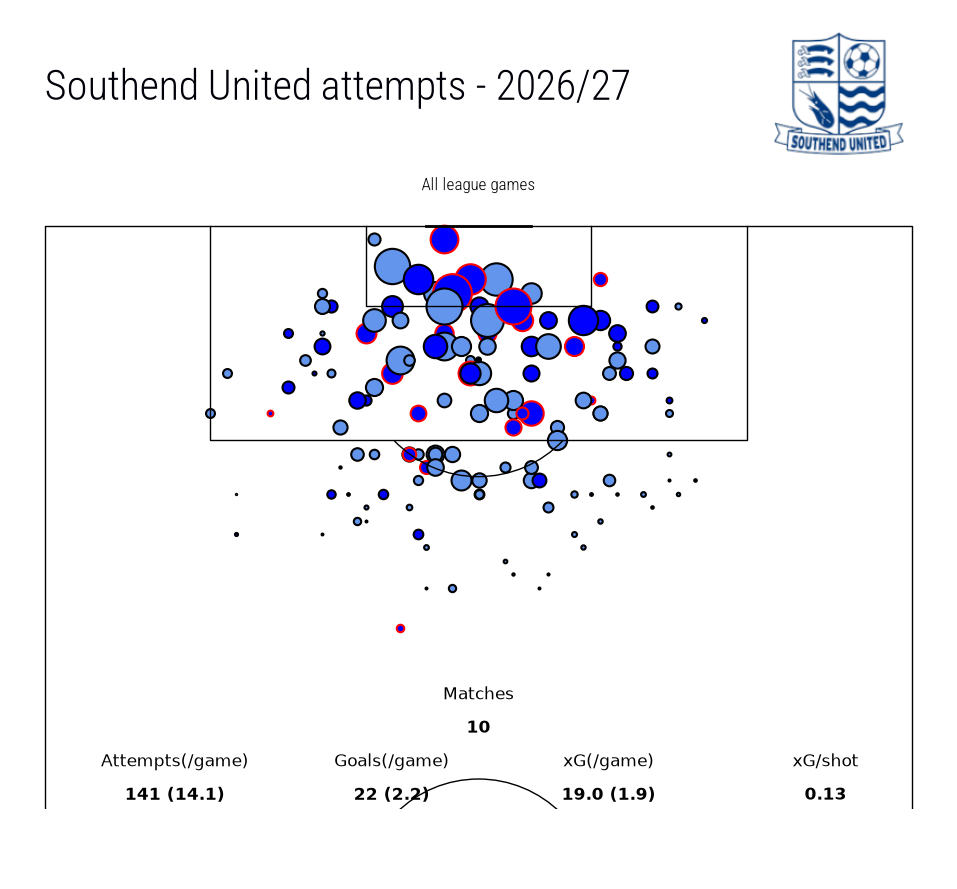

(<Figure size 1064.81x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=16.190476190476193, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [4]:
team.attempts_map(SOUTHEND, SEASON)

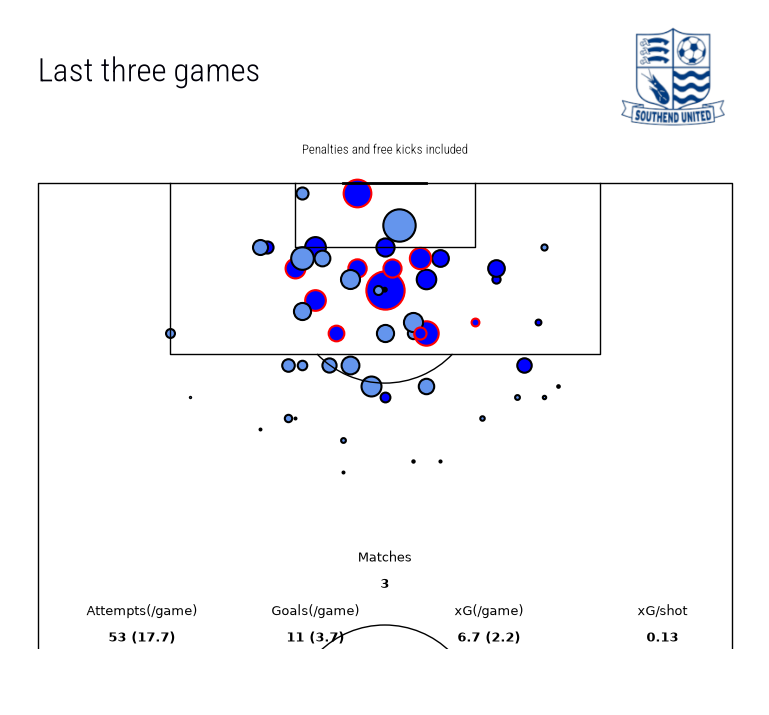

(<Figure size 851.849x800 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=16.190476190476193, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [5]:
team.attempts_map(SOUTHEND, SEASON, last_n=3, include_pens=True, include_free_kicks=True,
                  header="Last three games", labels=["Penalties and free kicks included"], fig_height=8)

Any split of the fixtures works. Home against away, using the venue in `season_results`:

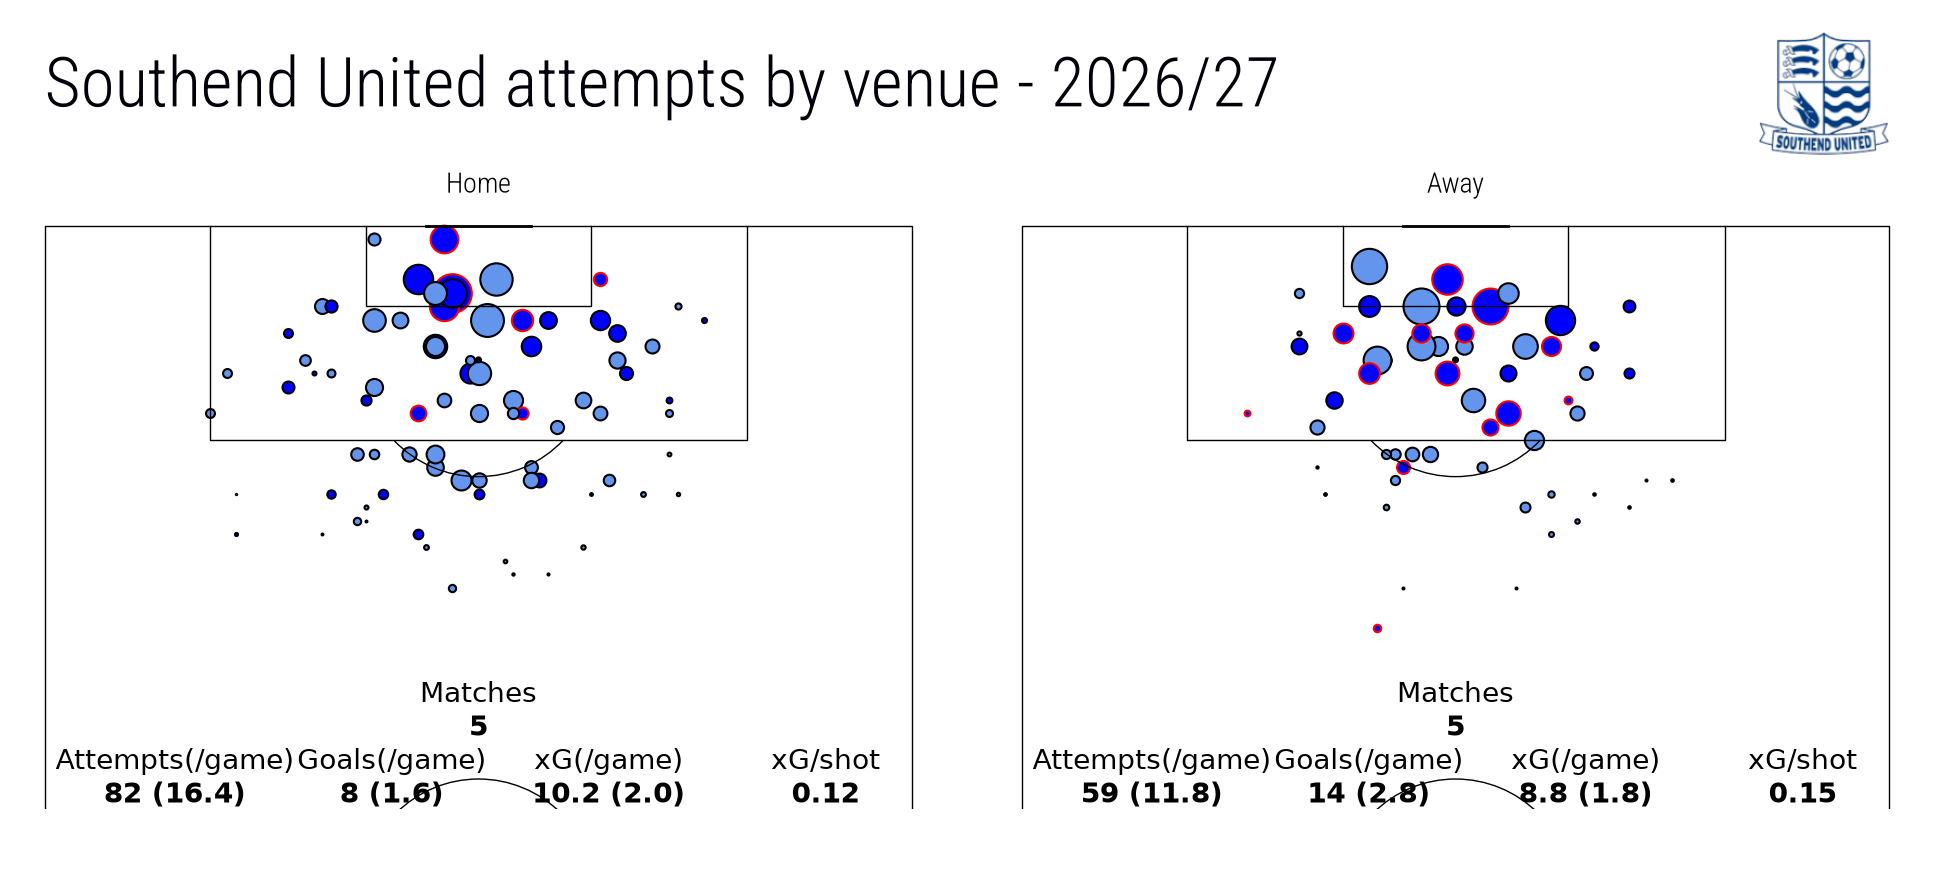

(<Figure size 2175.08x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=16.190476190476193, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [6]:
from wyscout.data.season import played_matches, season_results

results = season_results(SOUTHEND, SEASON)
fixtures = {m["matchId"]: m for m in played_matches(SOUTHEND, SEASON)}
home = [fixtures[r.match_id] for r in results.itertuples() if r.venue == "H"]
away = [fixtures[r.match_id] for r in results.itertuples() if r.venue == "A"]

team.attempts_map(SOUTHEND, SEASON, match_groups=[home, away], labels=["Home", "Away"],
                  header=f"Southend United attempts by venue - {season_label(SEASON)}")

## `team.attempts_by_possession` - with and without the ball

The same chart split at a possession percentage from the advanced match stats.

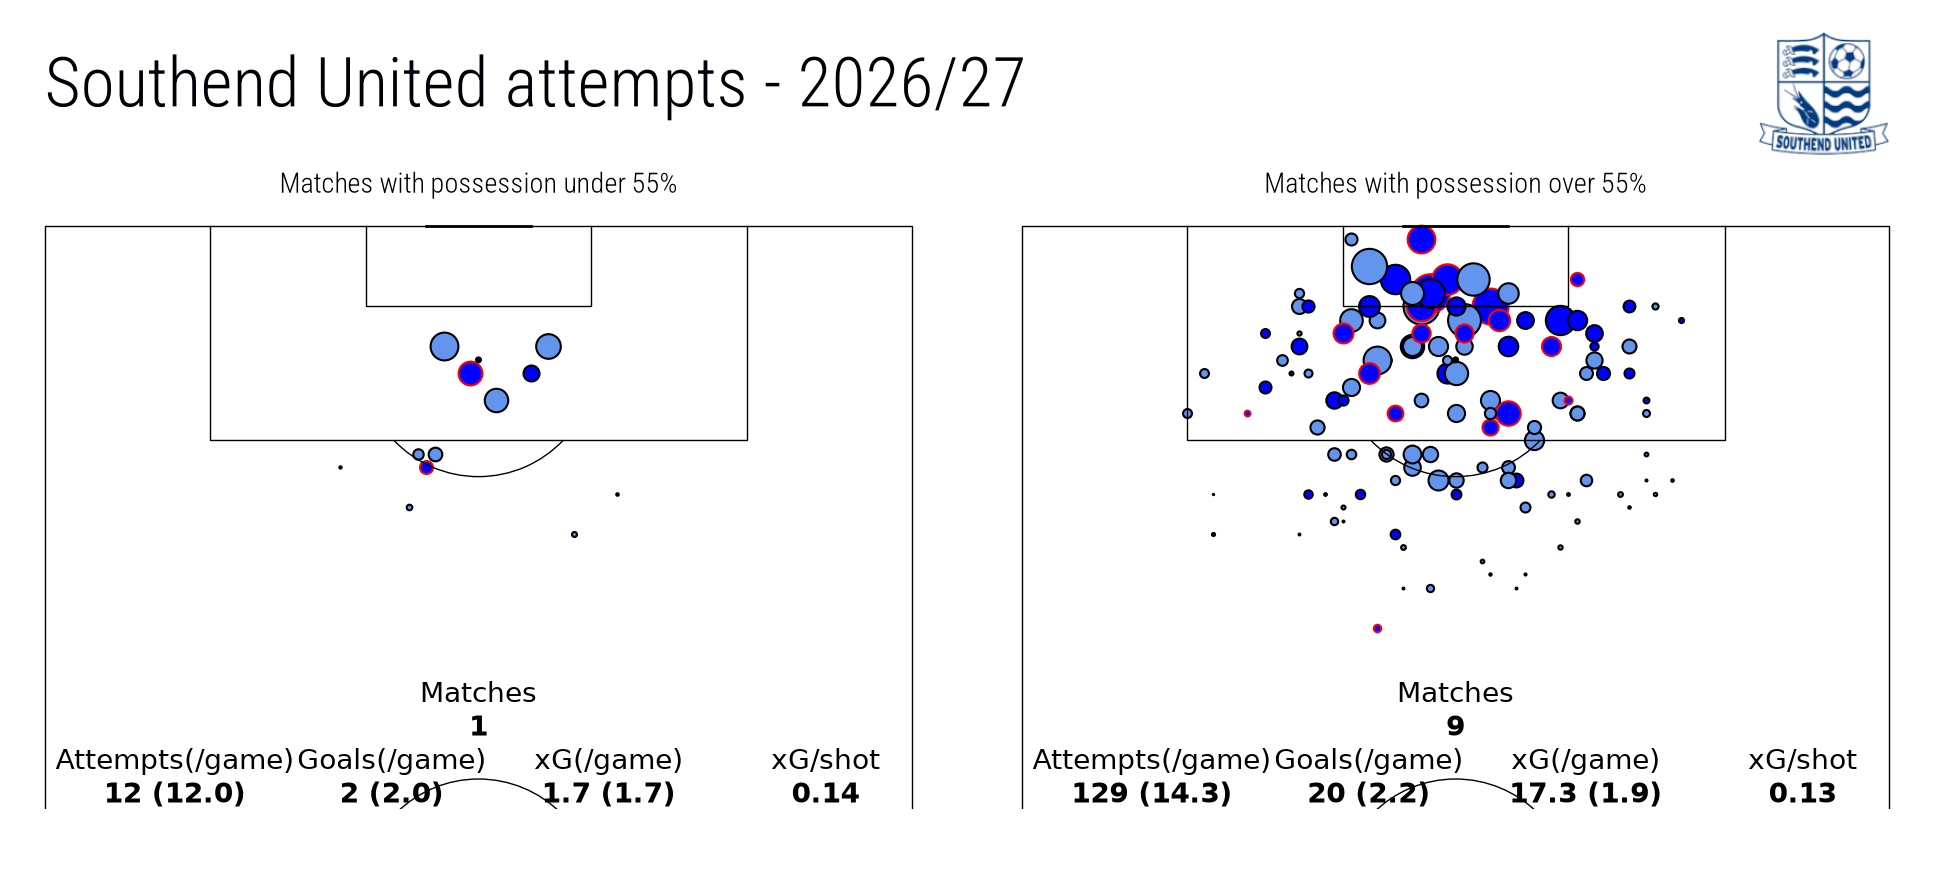

(<Figure size 2175.08x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=16.190476190476193, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [7]:
team.attempts_by_possession(SOUTHEND, SEASON, pct=55)

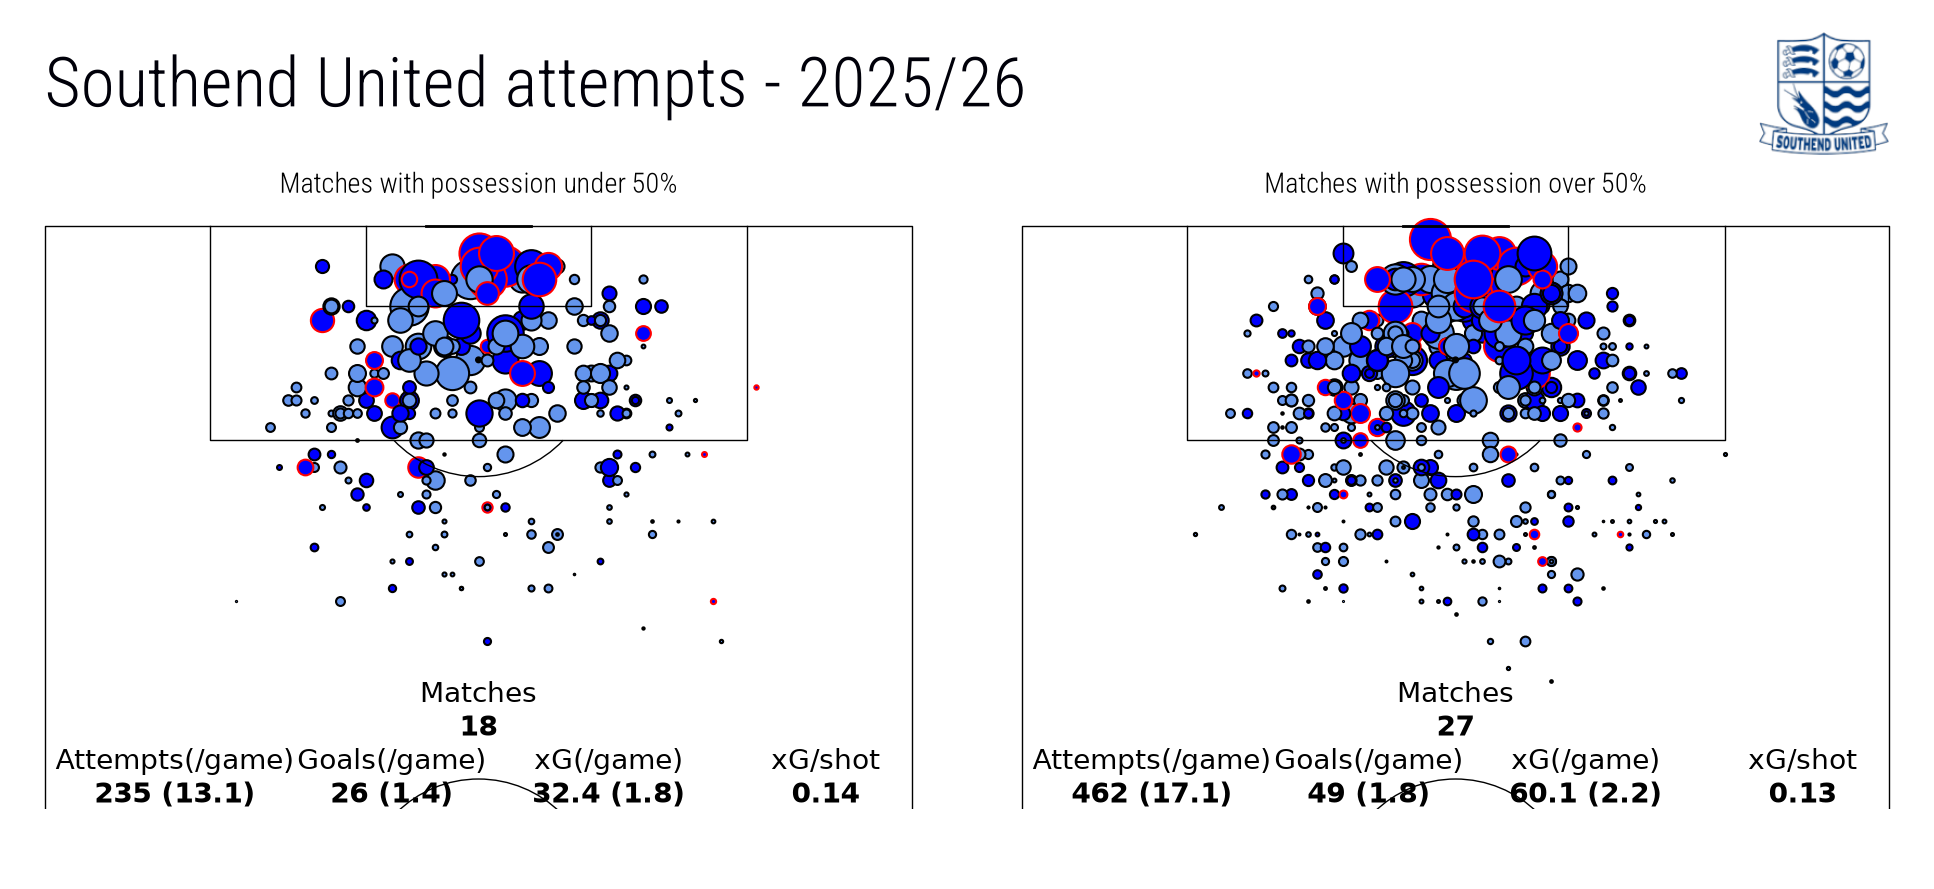

(<Figure size 2175.08x1000 with 5 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-6.476190476190477, pad_top=16.190476190476193, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [8]:
team.attempts_by_possession(SOUTHEND, PREV_SEASON, pct=50, fig_height=10)

## `team.attempts_heat_map` - where the shots come from

A density map of attempt locations rather than individual markers.

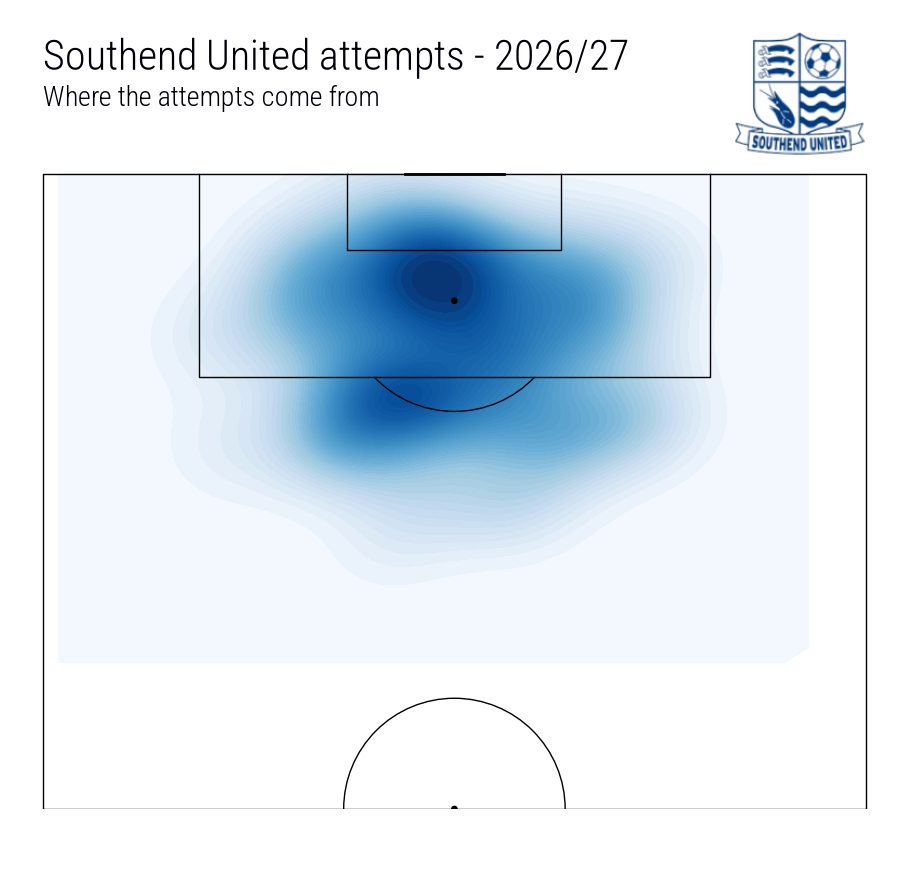

(<Figure size 1010.04x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [9]:
team.attempts_heat_map(SOUTHEND, SEASON, subtitle=["Where the attempts come from"])

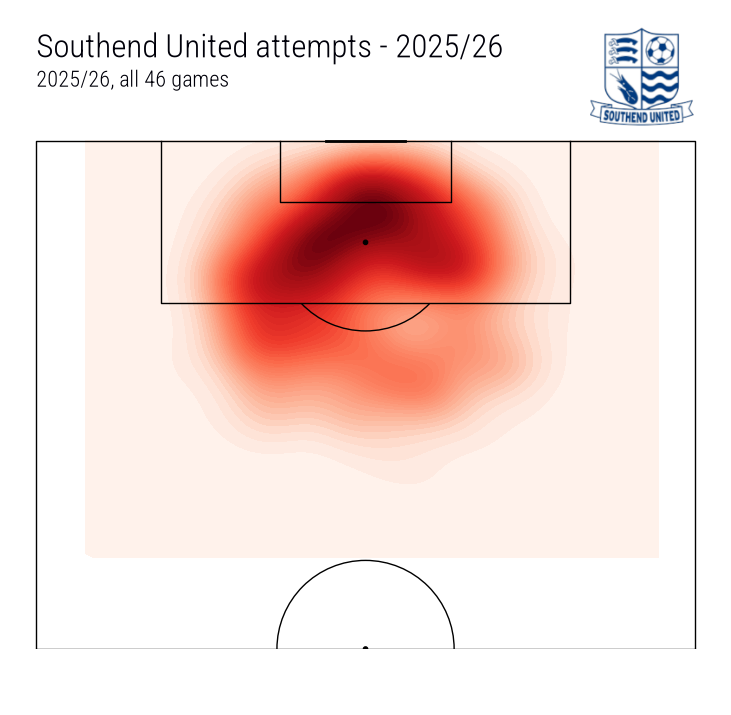

(<Figure size 808.032x800 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=12.952380952380954, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [10]:
team.attempts_heat_map(SOUTHEND, PREV_SEASON, subtitle=[f"{season_label(PREV_SEASON)}, all 46 games"], cmap="Reds", fig_height=8)

## `team.season_action_maps` - a pitch per match

Touch heat map, our attempts (blue, top) and the opposition's (grey, at our end) for every
match. `cols` sets the grid width, `last_n` limits to recent games, `oldest_first=False`
reverses the order.

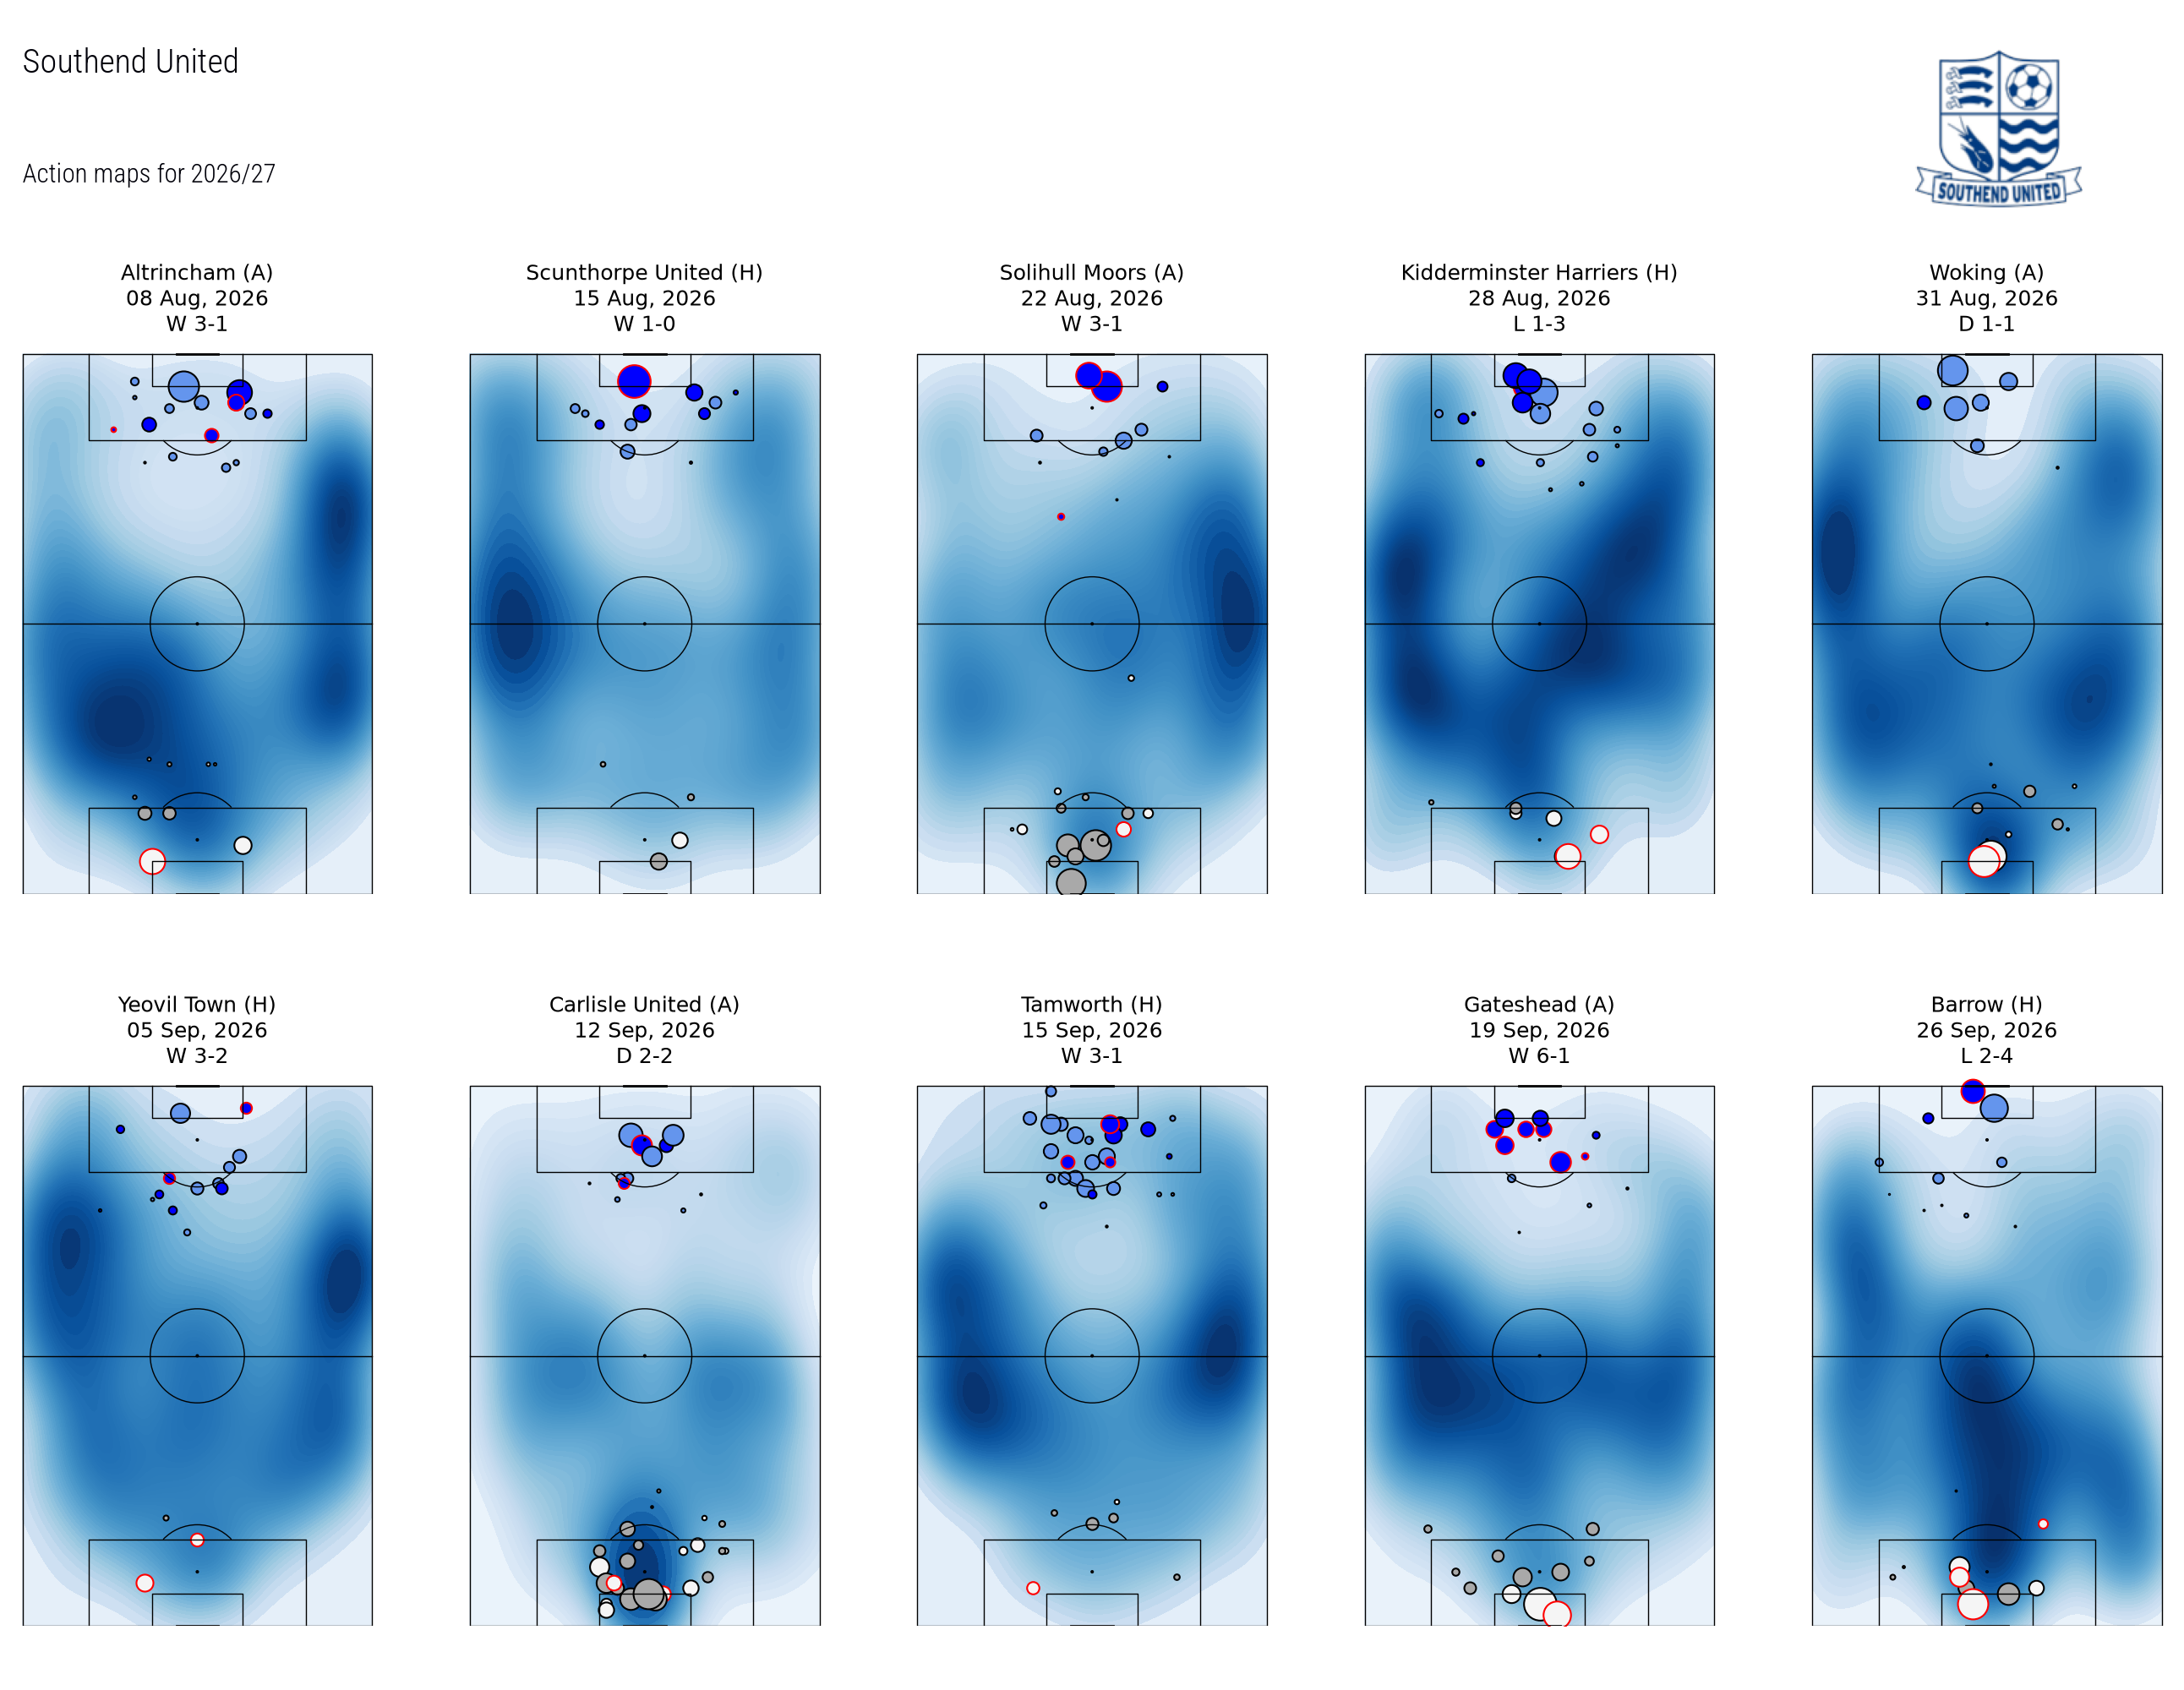

(<Figure size 2914.11x2200 with 13 Axes>,
 {'pitch': array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
         [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=22.666666666666668, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [11]:
team.season_action_maps(SOUTHEND, SEASON, cols=5, fig_height=22)

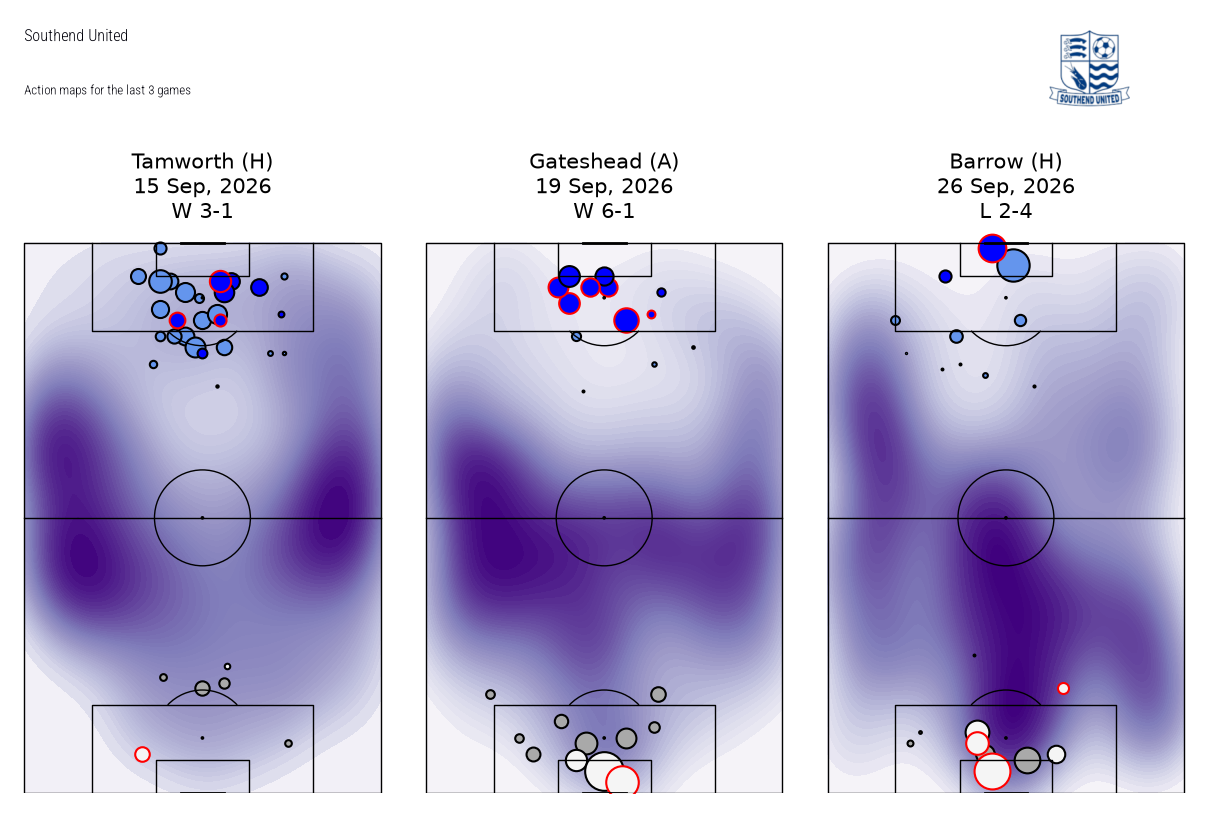

(<Figure size 1350.43x900 with 6 Axes>,
 {'pitch': array([<Axes: >, <Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='black', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=22.666666666666668, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [12]:
team.season_action_maps(SOUTHEND, SEASON, last_n=3, cols=3, fig_height=9, cmap="Purples")

## `team.shots_first_vs_last` - has the shot profile changed?

Attempts from the first N games beside the last N. With neither given the season is halved.

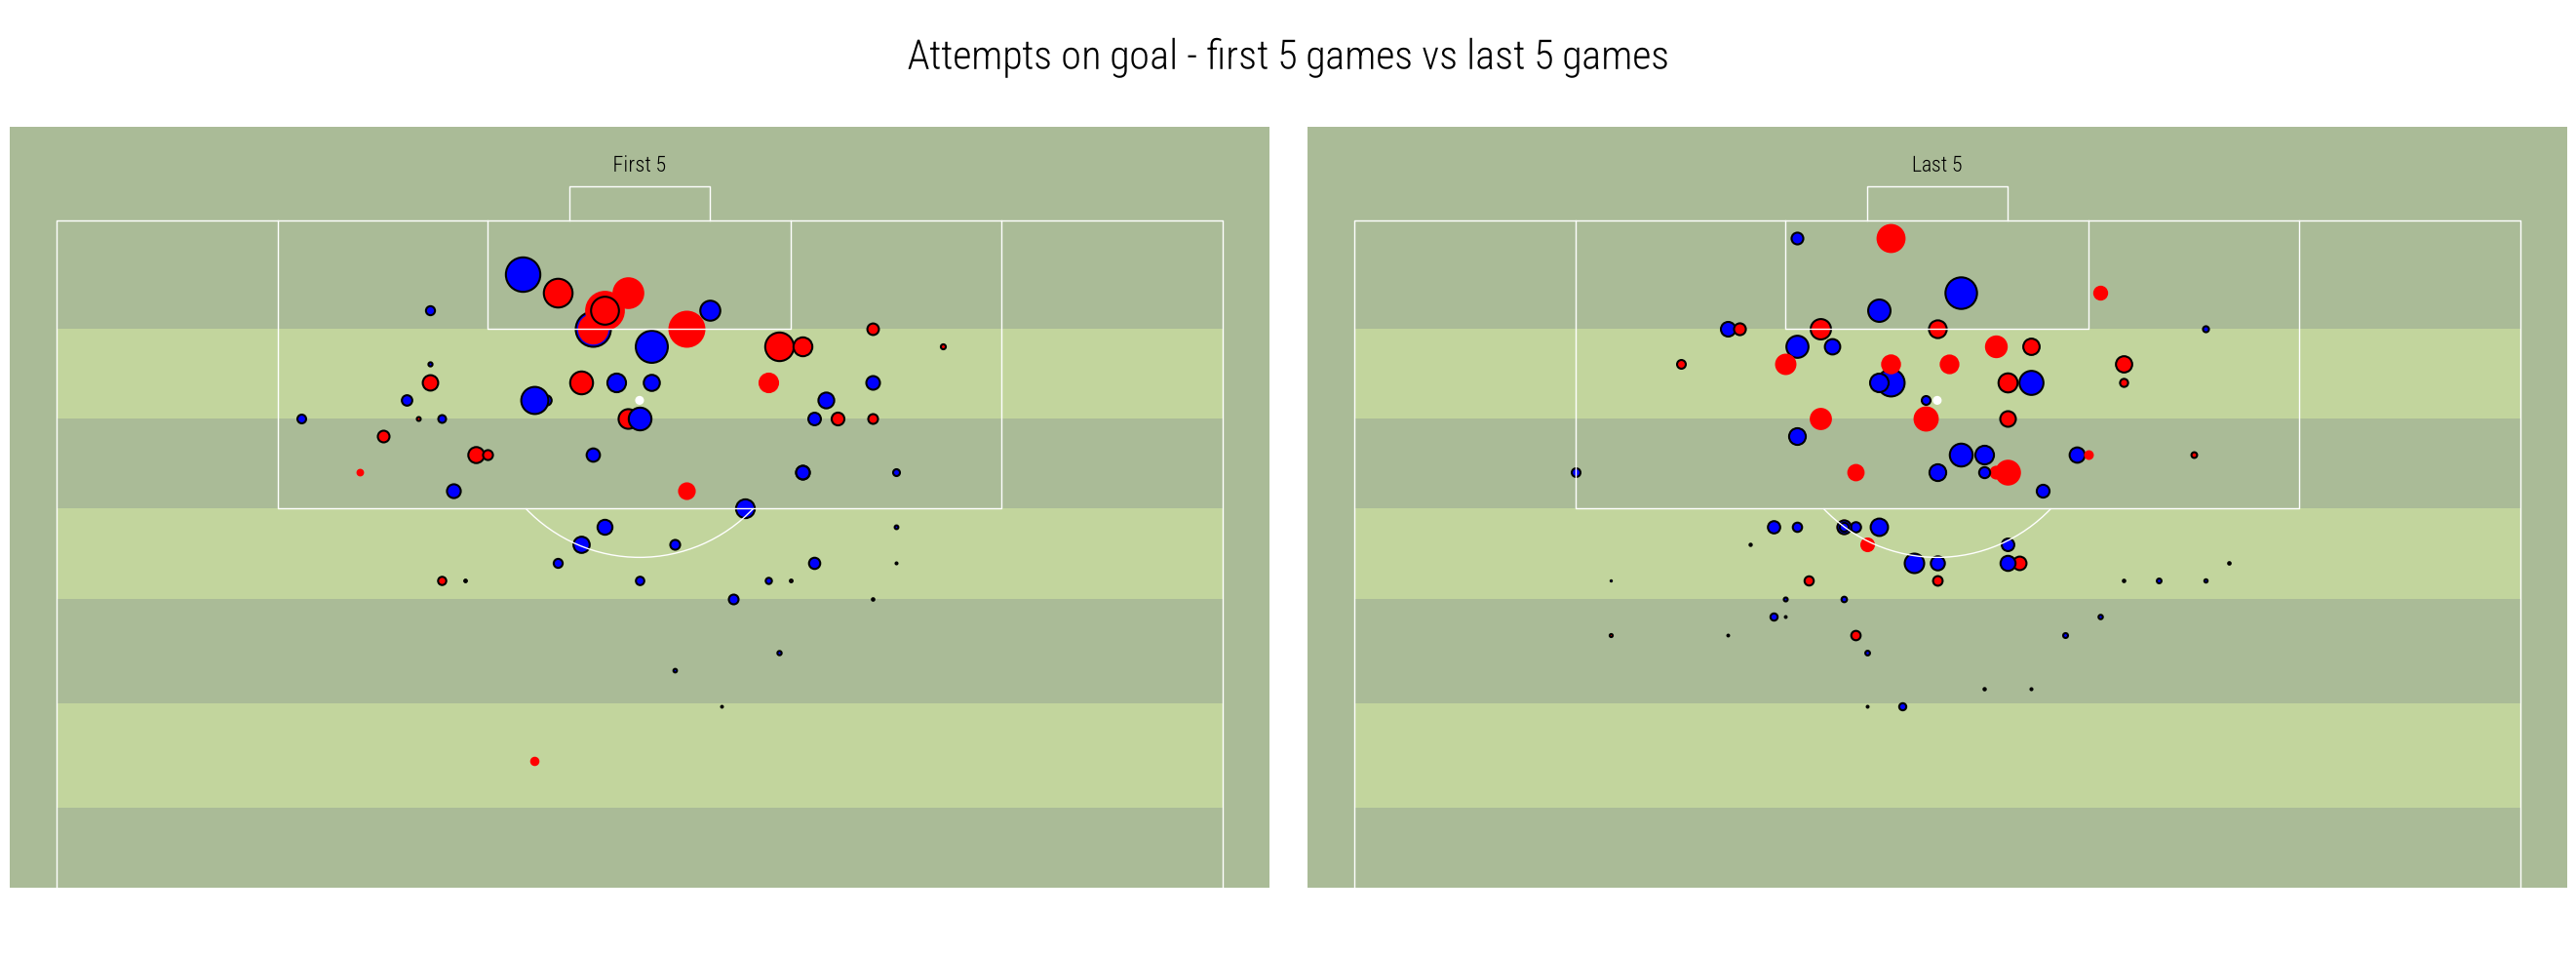

(<Figure size 2980.47x1000 with 4 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [13]:
team.shots_first_vs_last(SOUTHEND, SEASON)

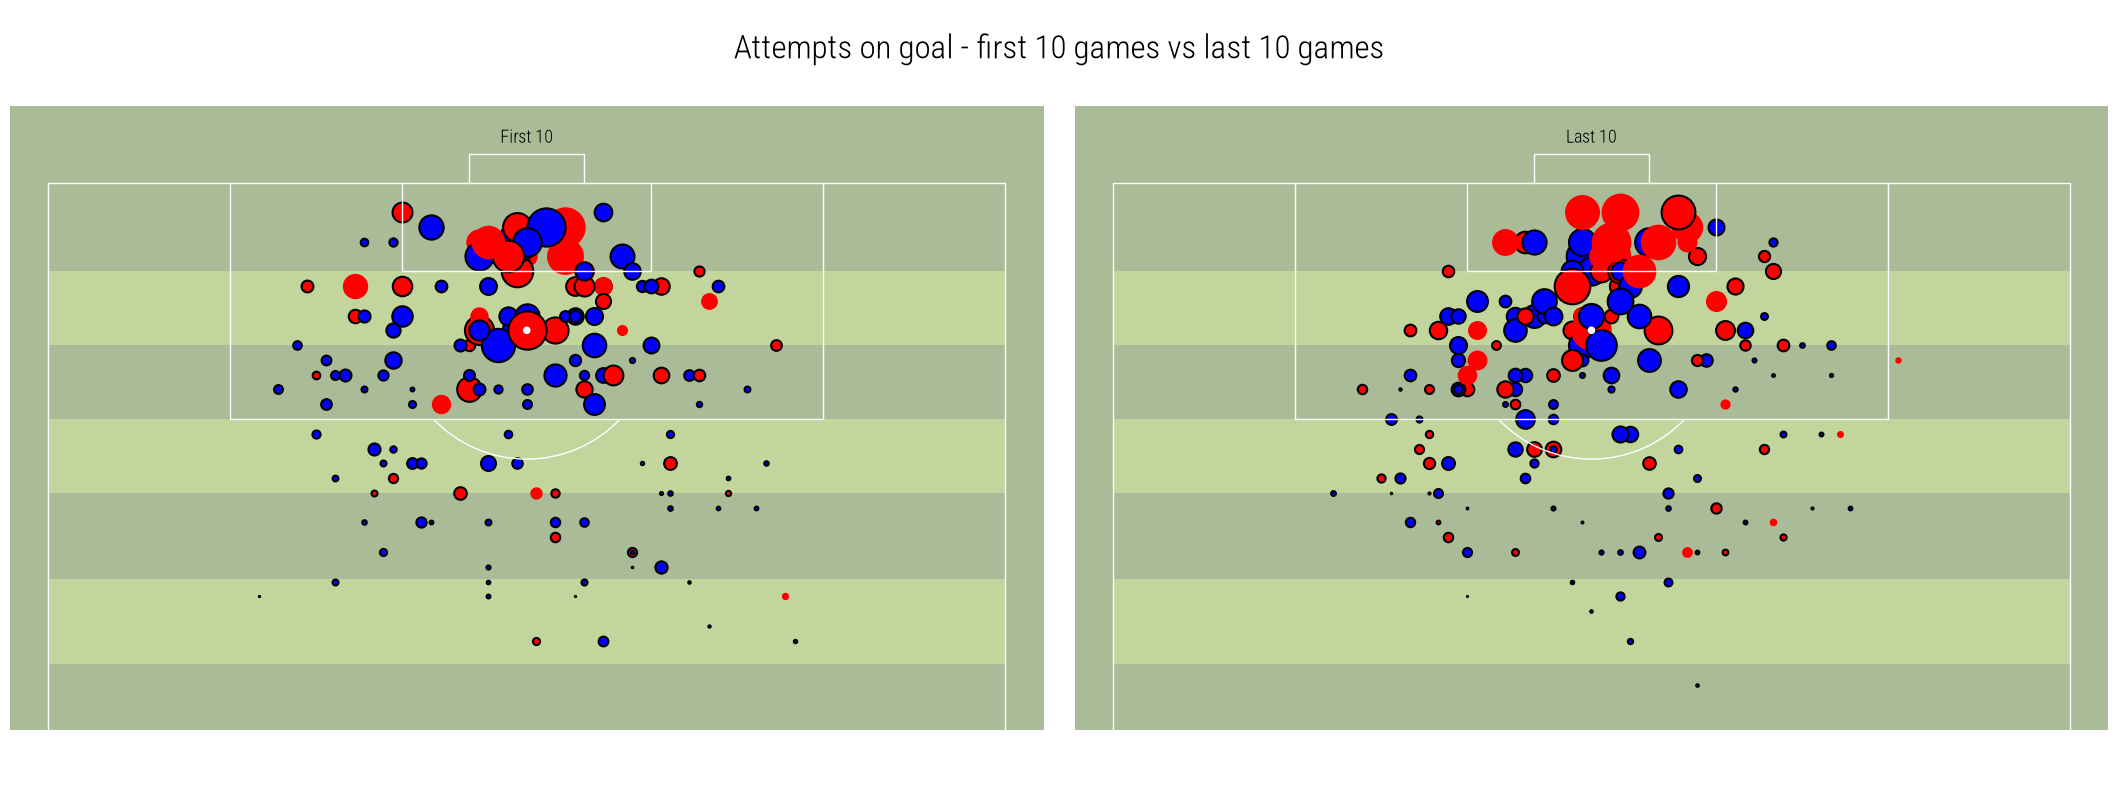

(<Figure size 2384.38x800 with 4 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [14]:
team.shots_first_vs_last(SOUTHEND, PREV_SEASON, first_n=10, last_n=10, include_pens=True, fig_height=8)

## `team.shots_for_and_against`

Our attempts beside every attempt we faced - over the season, or over the fixtures you pass.

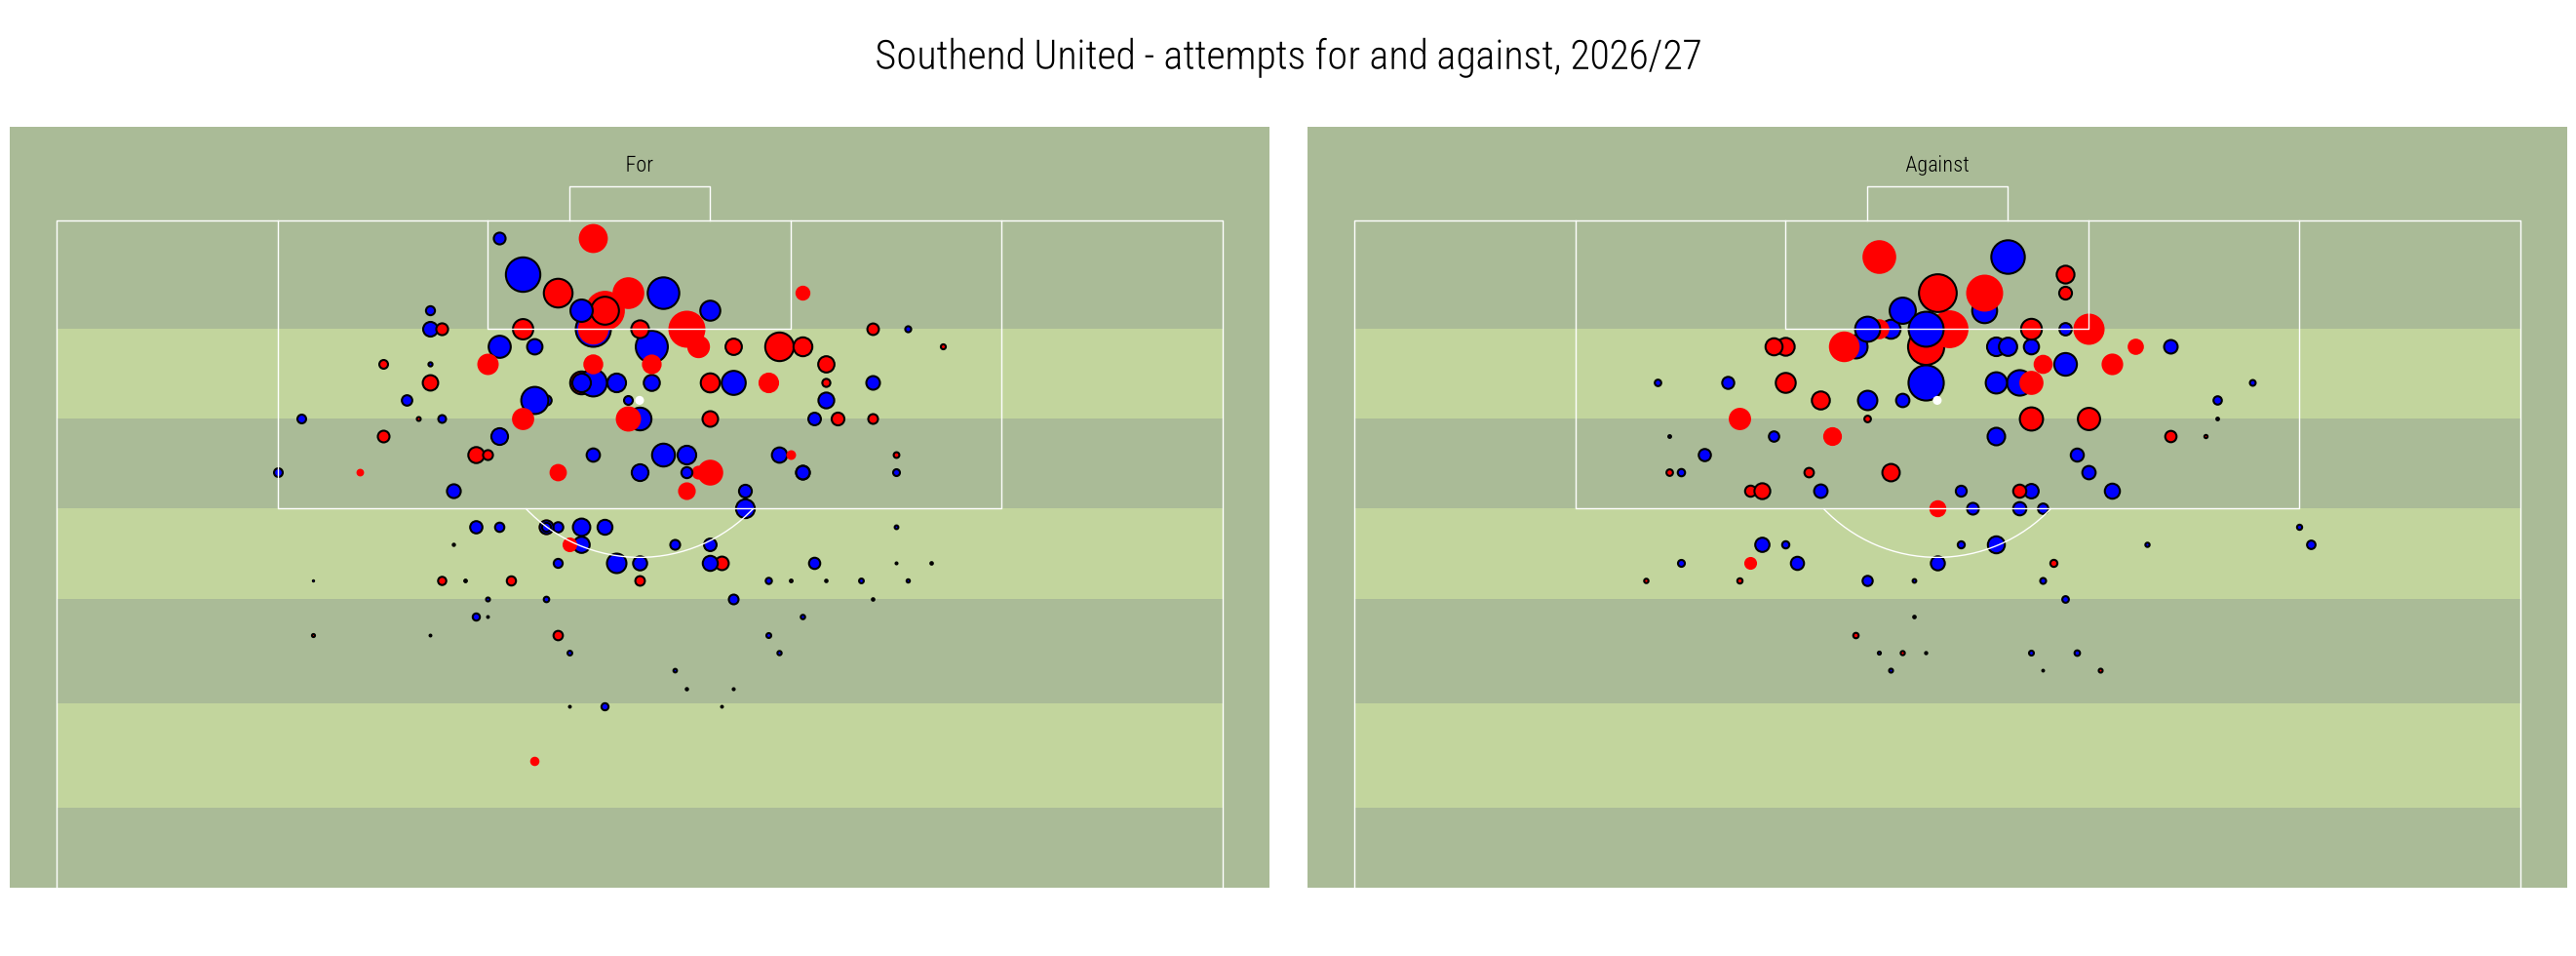

(<Figure size 2980.47x1000 with 4 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [15]:
team.shots_for_and_against(SOUTHEND, SEASON)

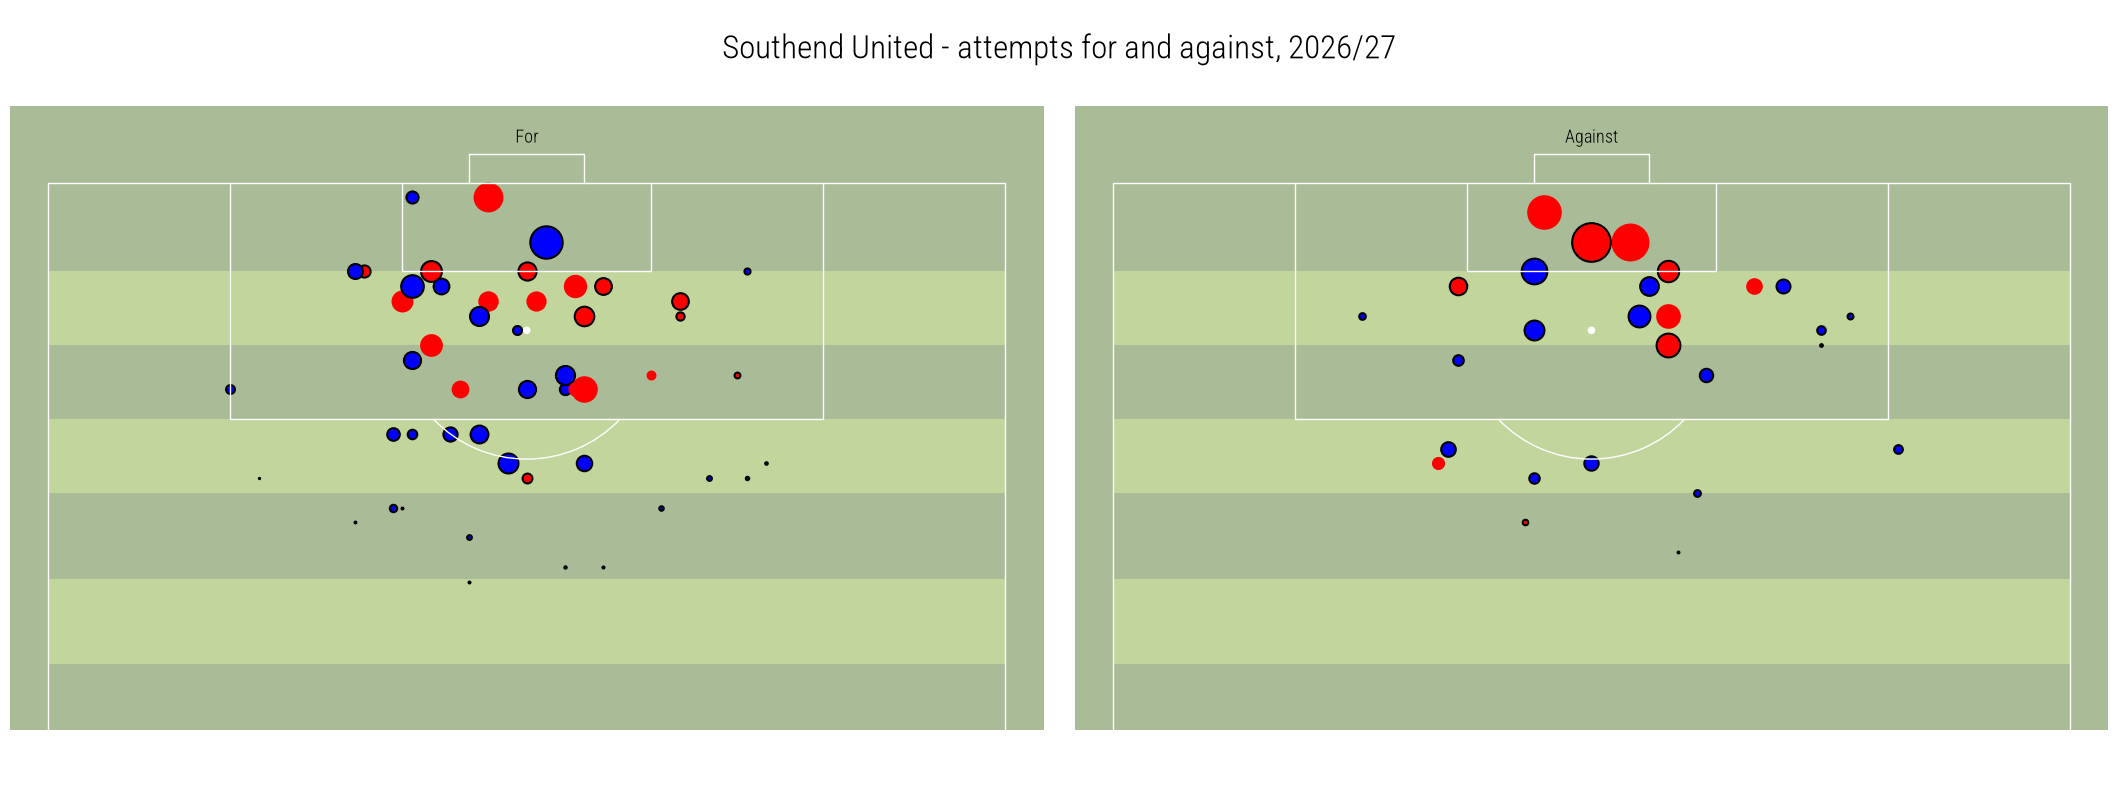

(<Figure size 2384.38x800 with 4 Axes>,
 {'pitch': array([<Axes: >, <Axes: >], dtype=object),
  'title': <Axes: >,
  'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [16]:
team.shots_for_and_against(SOUTHEND, SEASON, matches=played_matches(SOUTHEND, SEASON, oldest_first=False)[:3], fig_height=8)

## `team.attacking_stats` - per-player shooting

Four stacked bars per player: finishing (post-shot xG minus xG), xG against goals, attempts
against on target, and xG per attempt. Colours are (main, secondary).

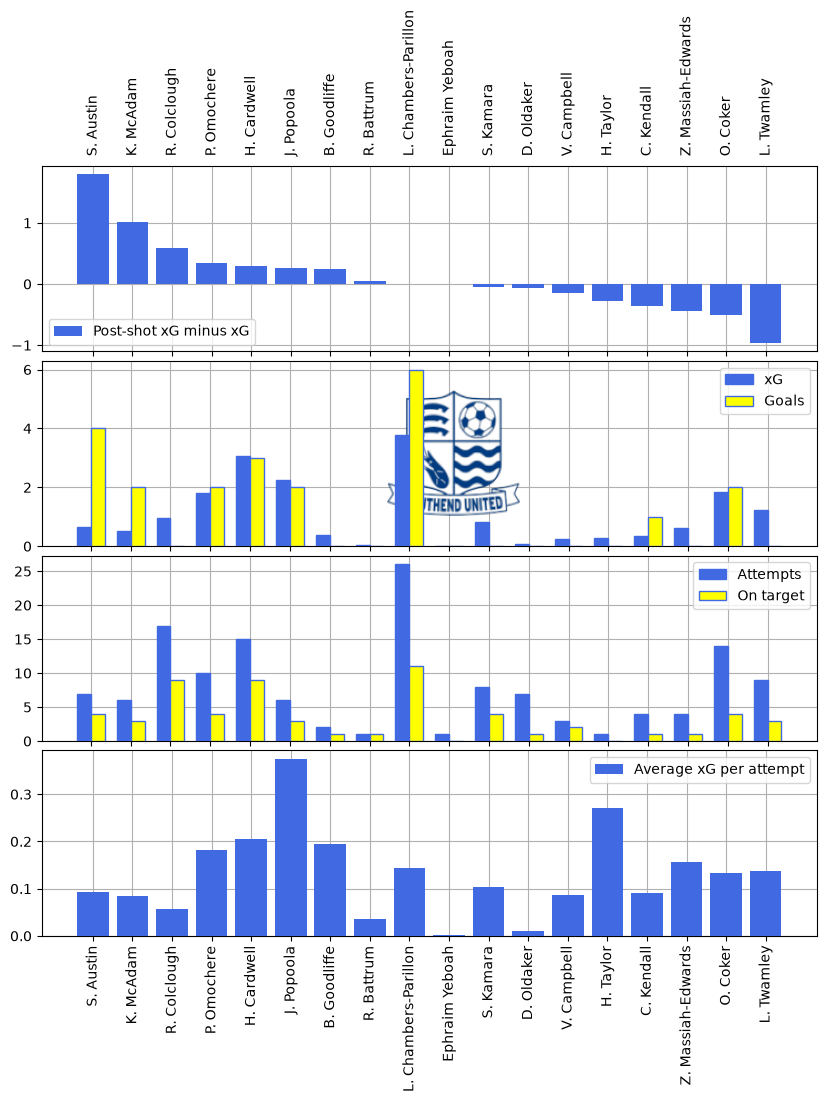

(<Figure size 1000x1000 with 4 Axes>, (<Axes: >, <Axes: >, <Axes: >, <Axes: >))

In [17]:
team.attacking_stats(SOUTHEND, SEASON)

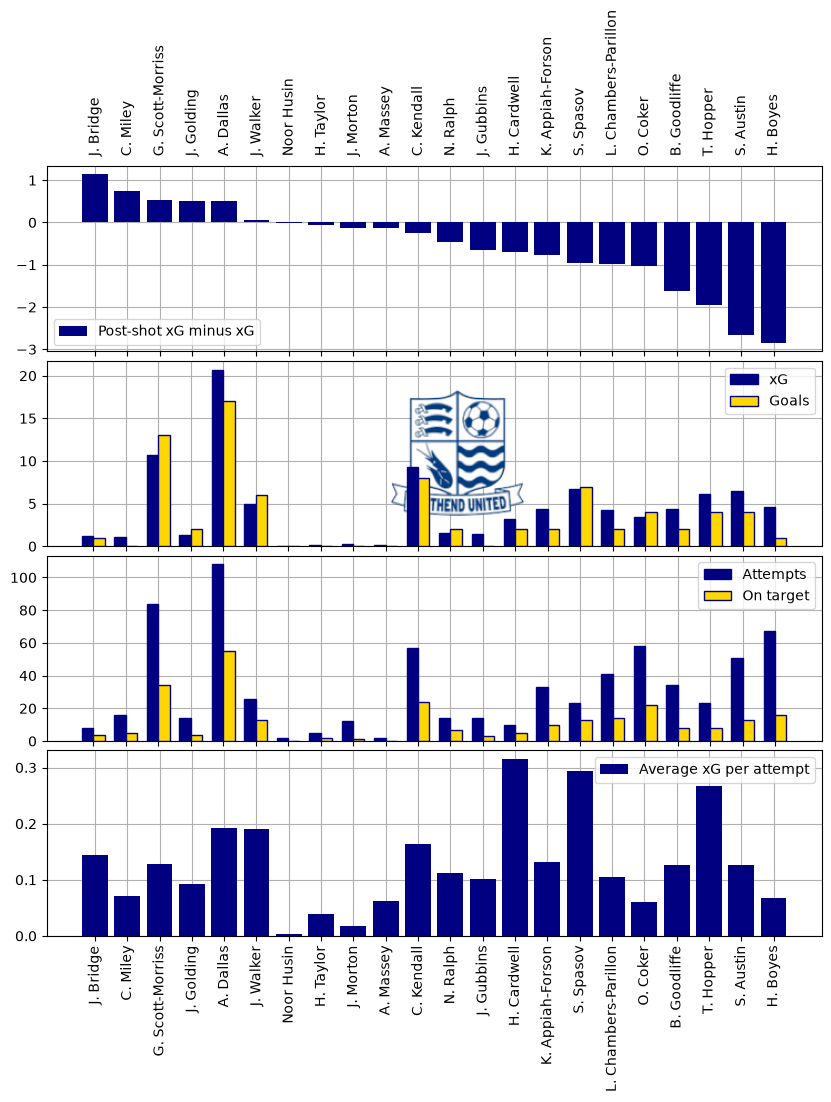

(<Figure size 1000x1000 with 4 Axes>, (<Axes: >, <Axes: >, <Axes: >, <Axes: >))

In [18]:
team.attacking_stats(SOUTHEND, PREV_SEASON, colors=["navy", "gold"], edgecolors=["navy", "navy"], include_pens=True)

## `team.key_passes_map`

Every key pass in the last N games on a striped half pitch; `highlight_players` draws theirs in
red.

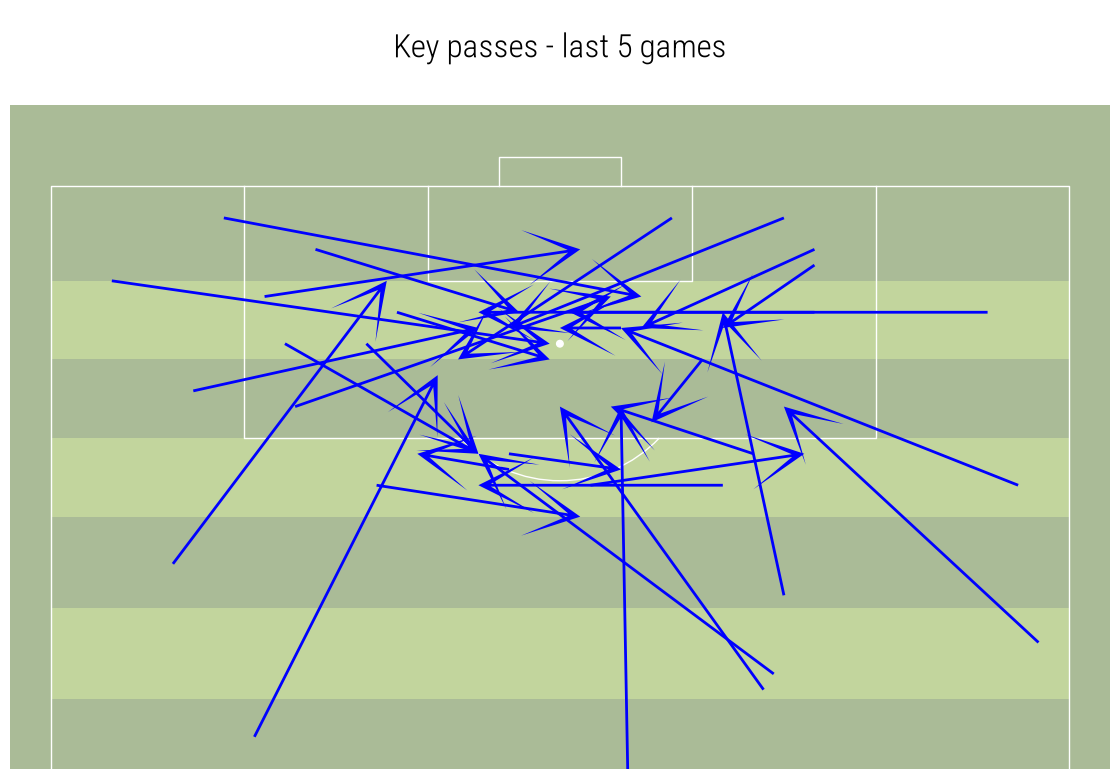

(<Figure size 1249.75x800 with 2 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [19]:
team.key_passes_map(SOUTHEND, SEASON, last_n=5)

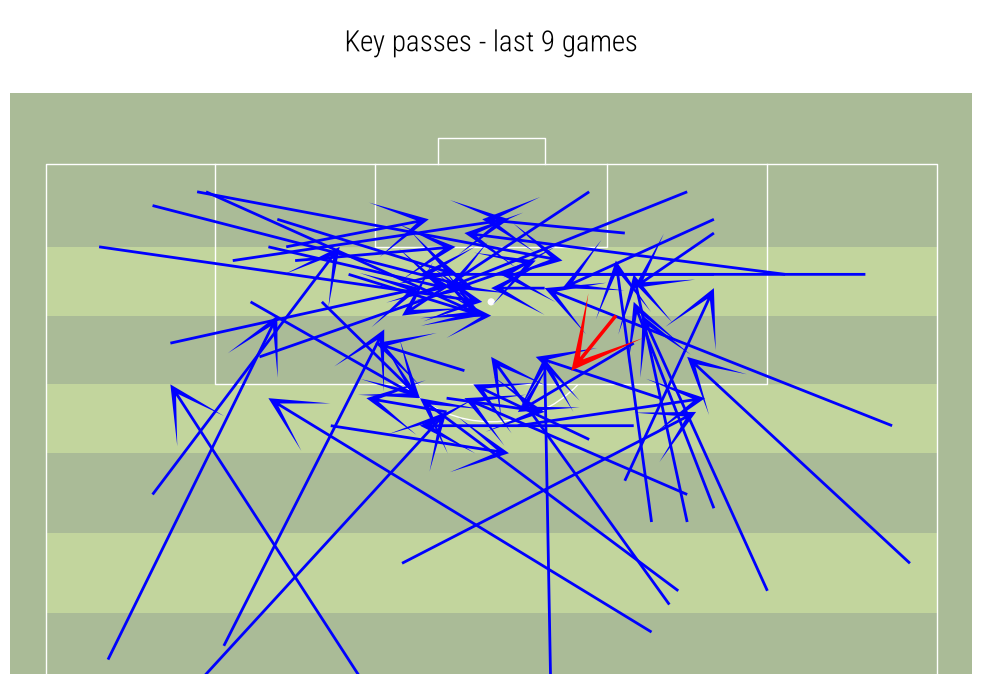

(<Figure size 1093.53x700 with 2 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=True, pitch_color='#aabb97', line_color='white', linewidth=1, line_zorder=2, linestyle=None, stripe=True, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=-12.952380952380954, pad_top=5.180952380952381, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='box', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [20]:
team.key_passes_map(SOUTHEND, SEASON, last_n=9, highlight_players=[H_CARDWELL], fig_height=7)

## `season.xg_trend`, `season.xg_vs_goals`, `season.cumulative_xg`

Three views of the same per-match table (`wyscout.data.season.season_shot_table`):

- **xg_trend** - xG per shot per match with rolling averages, attempts and goals on the right
  axis, results shaded behind
- **xg_vs_goals** - paired bars of xG and goals with a five-game rolling xG line
- **cumulative_xg** - the running totals and the gap between them, on a dark background

`include_pens=True` counts penalties in all three.

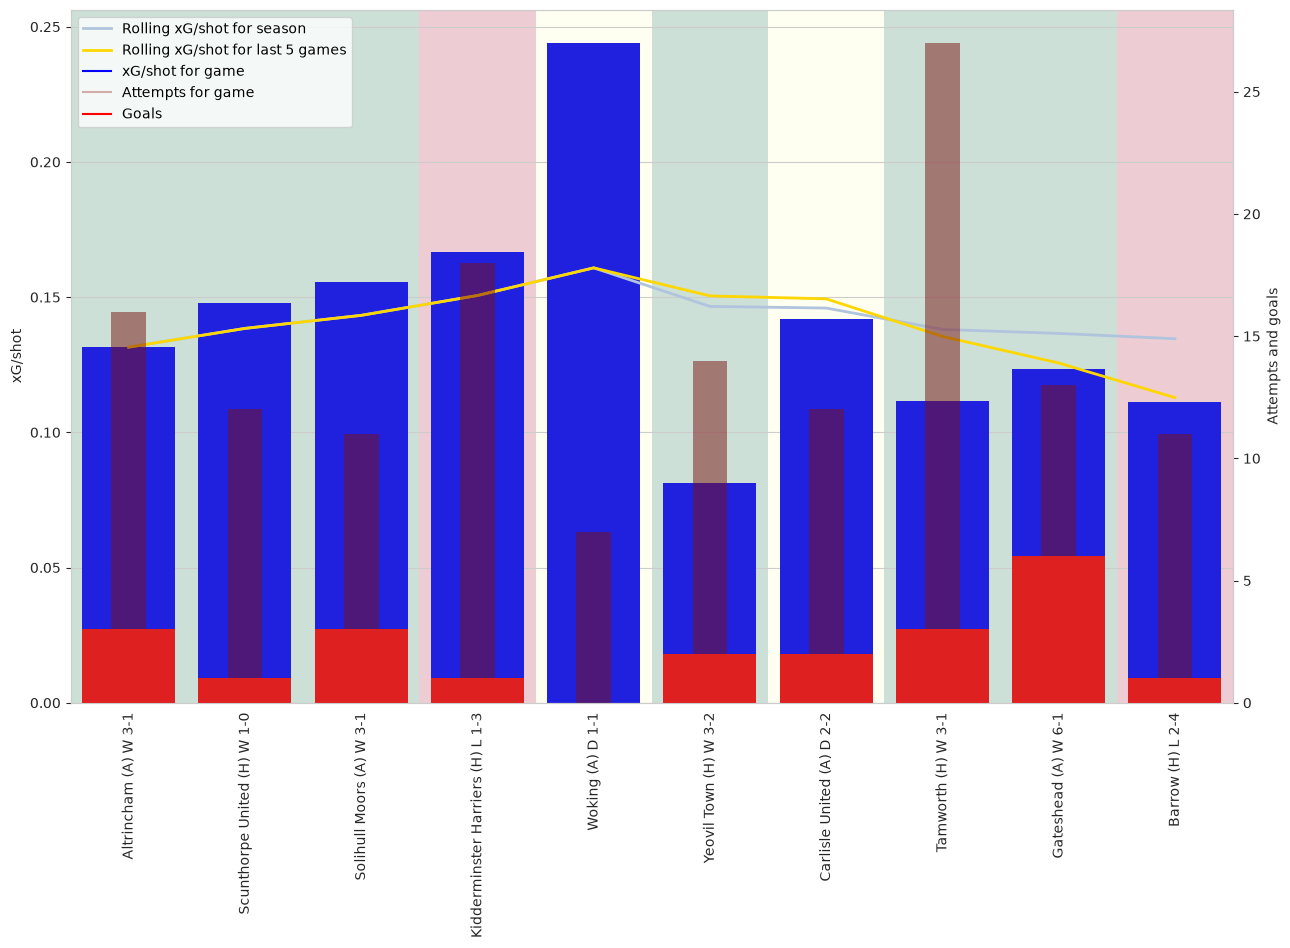

(<Figure size 1500x900 with 2 Axes>,
 (<Axes: ylabel='xG/shot'>,
  <Axes: xlabel='label', ylabel='Attempts and goals'>))

In [21]:
season.xg_trend(SOUTHEND, SEASON)

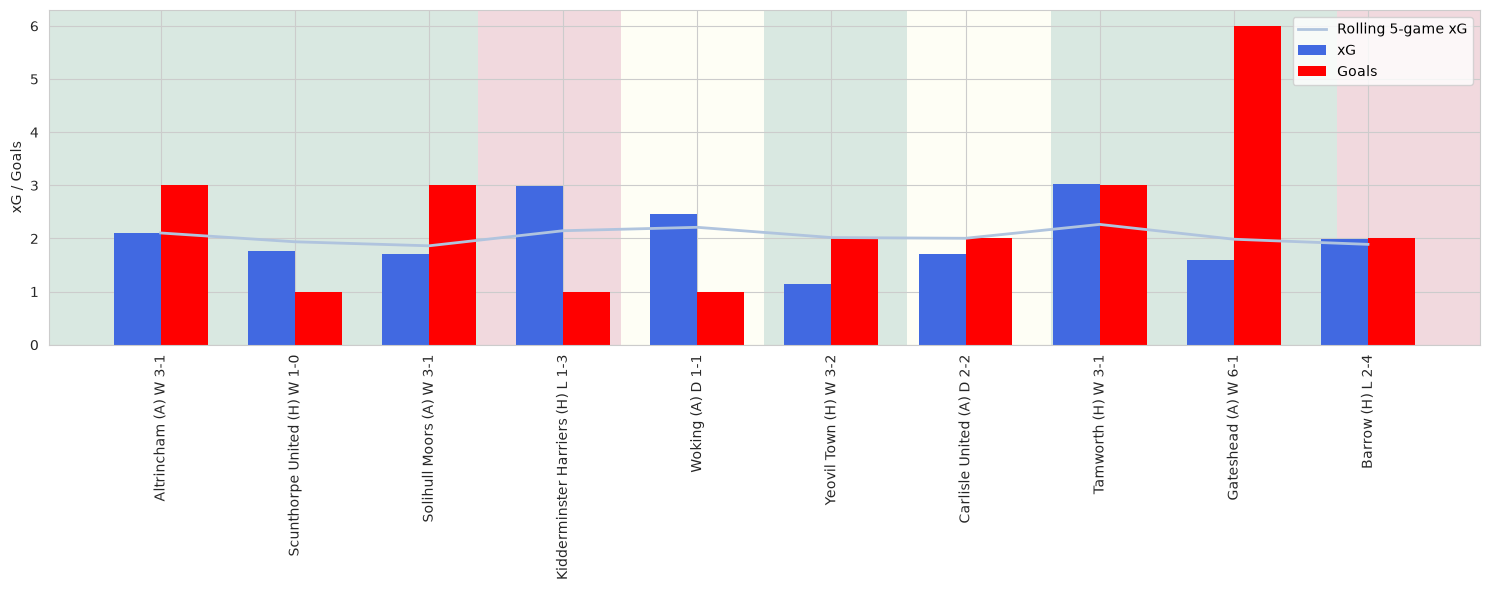

(<Figure size 1500x600 with 1 Axes>, <Axes: ylabel='xG / Goals'>)

In [22]:
season.xg_vs_goals(SOUTHEND, SEASON, include_pens=True)

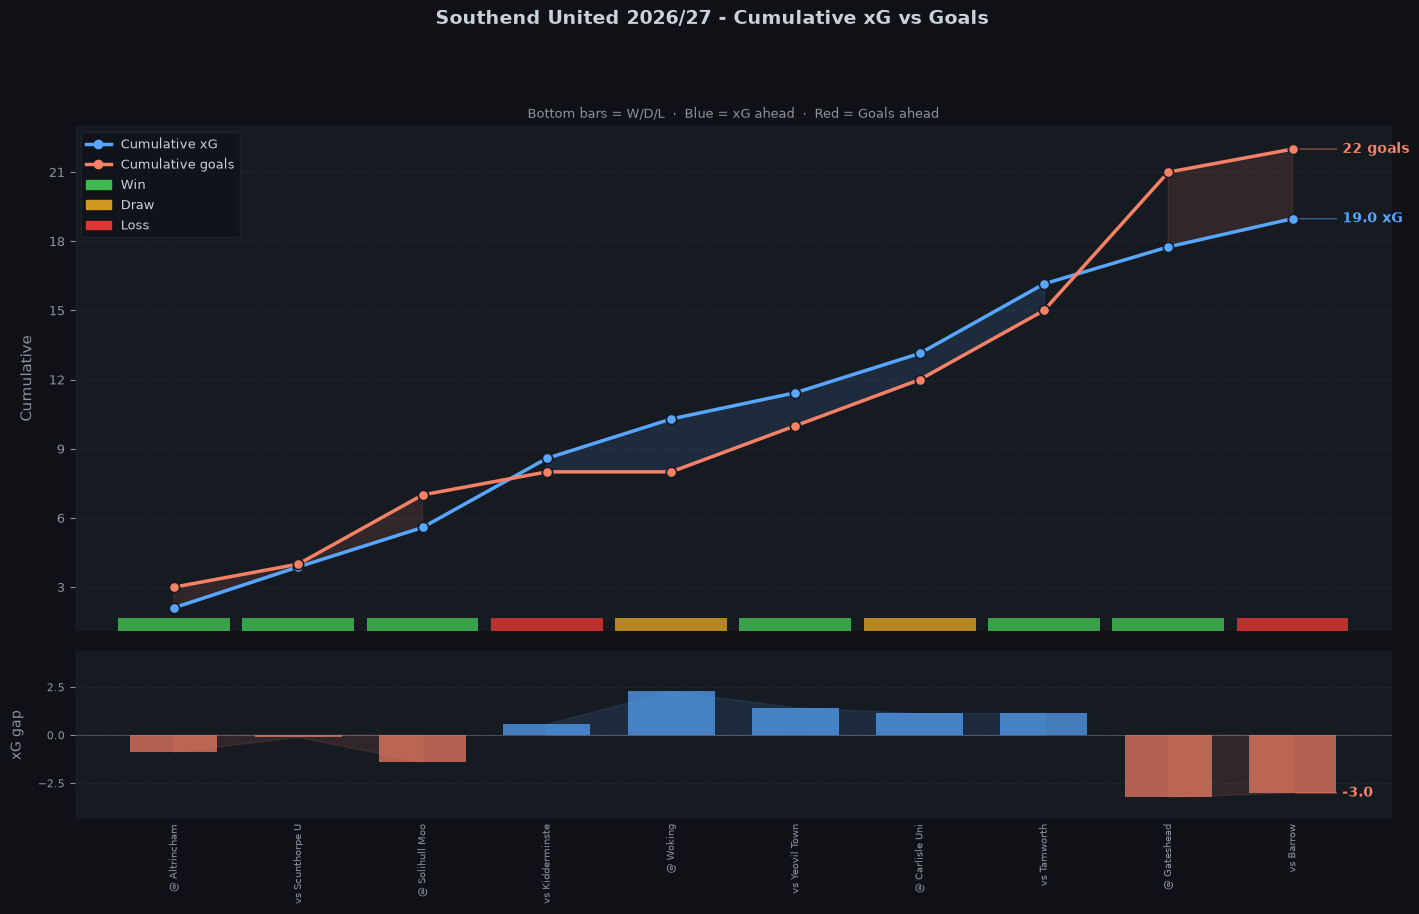

(<Figure size 1700x900 with 2 Axes>,
 (<Axes: title={'center': 'Bottom bars = W/D/L  ·  Blue = xG ahead  ·  Red = Goals ahead'}, ylabel='Cumulative'>,
  <Axes: ylabel='xG gap'>))

In [23]:
season.cumulative_xg(SOUTHEND, SEASON)

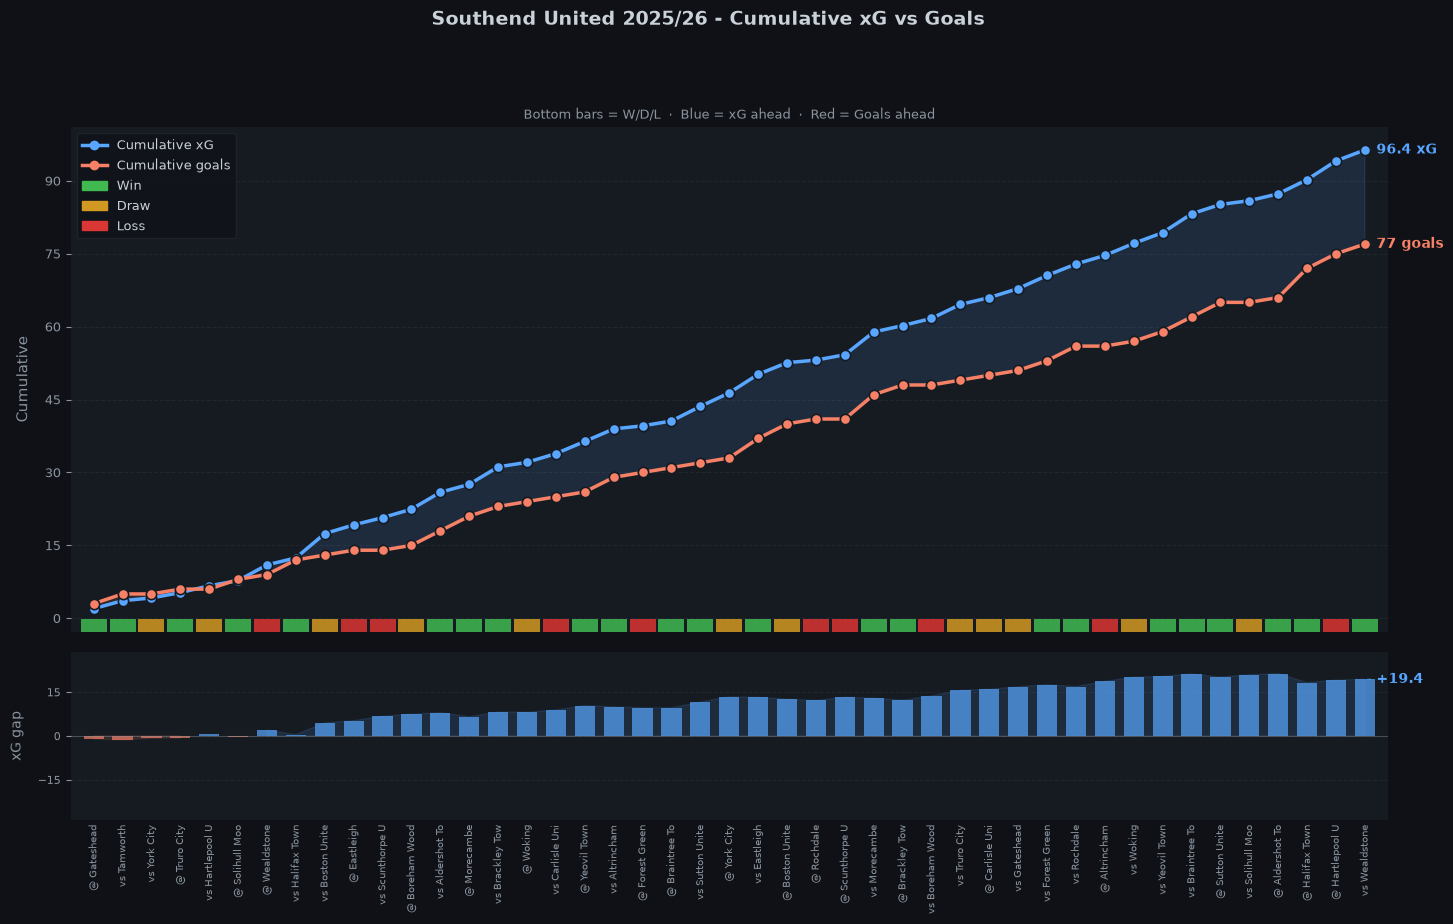

(<Figure size 1700x900 with 2 Axes>,
 (<Axes: title={'center': 'Bottom bars = W/D/L  ·  Blue = xG ahead  ·  Red = Goals ahead'}, ylabel='Cumulative'>,
  <Axes: ylabel='xG gap'>))

In [24]:
season.cumulative_xg(SOUTHEND, PREV_SEASON, include_pens=True)

## `season.season_comparison` - this season against another

A results table lined up by game number (with last season's result in the same fixture as a
bonus column) and cumulative points, goal difference and goals at the same stage. The second
id is the season to compare with.

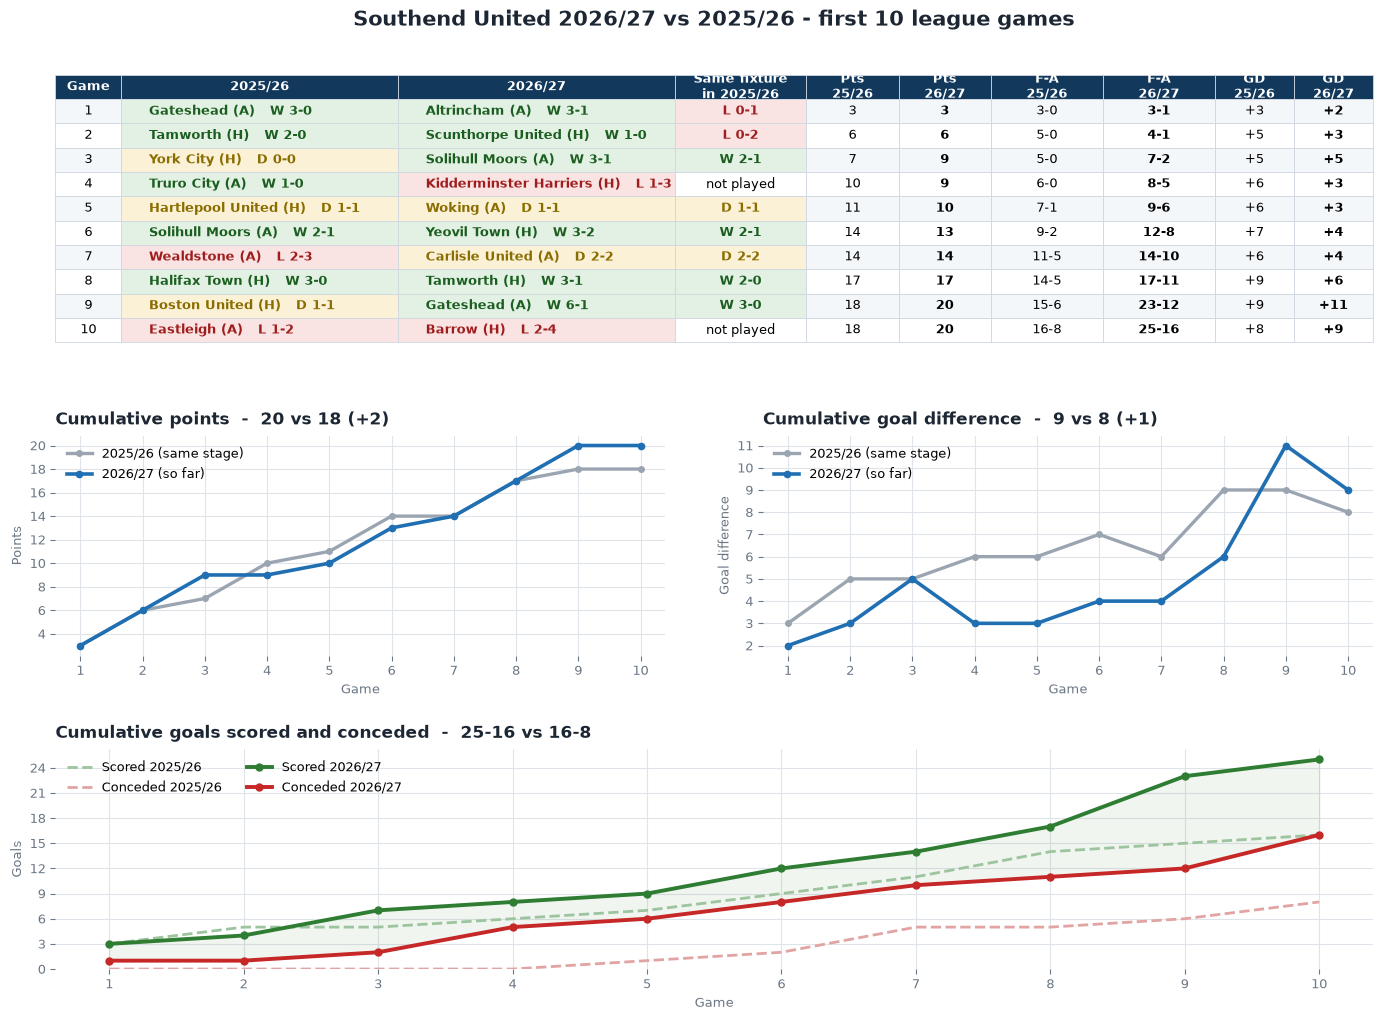

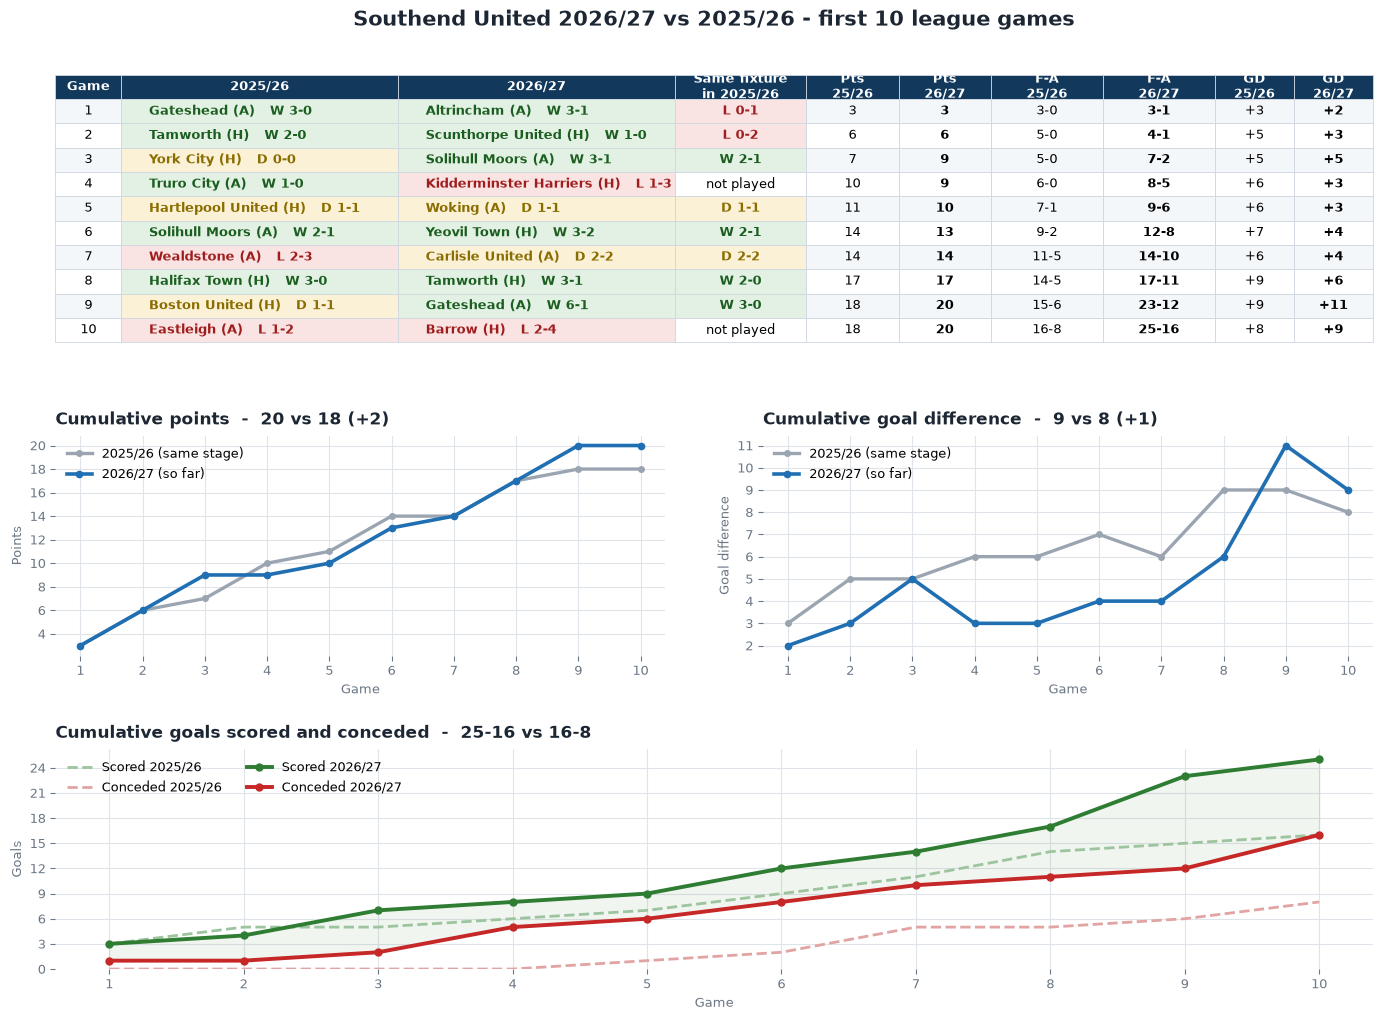

In [25]:
season.season_comparison(SOUTHEND, SEASON, PREV_SEASON)

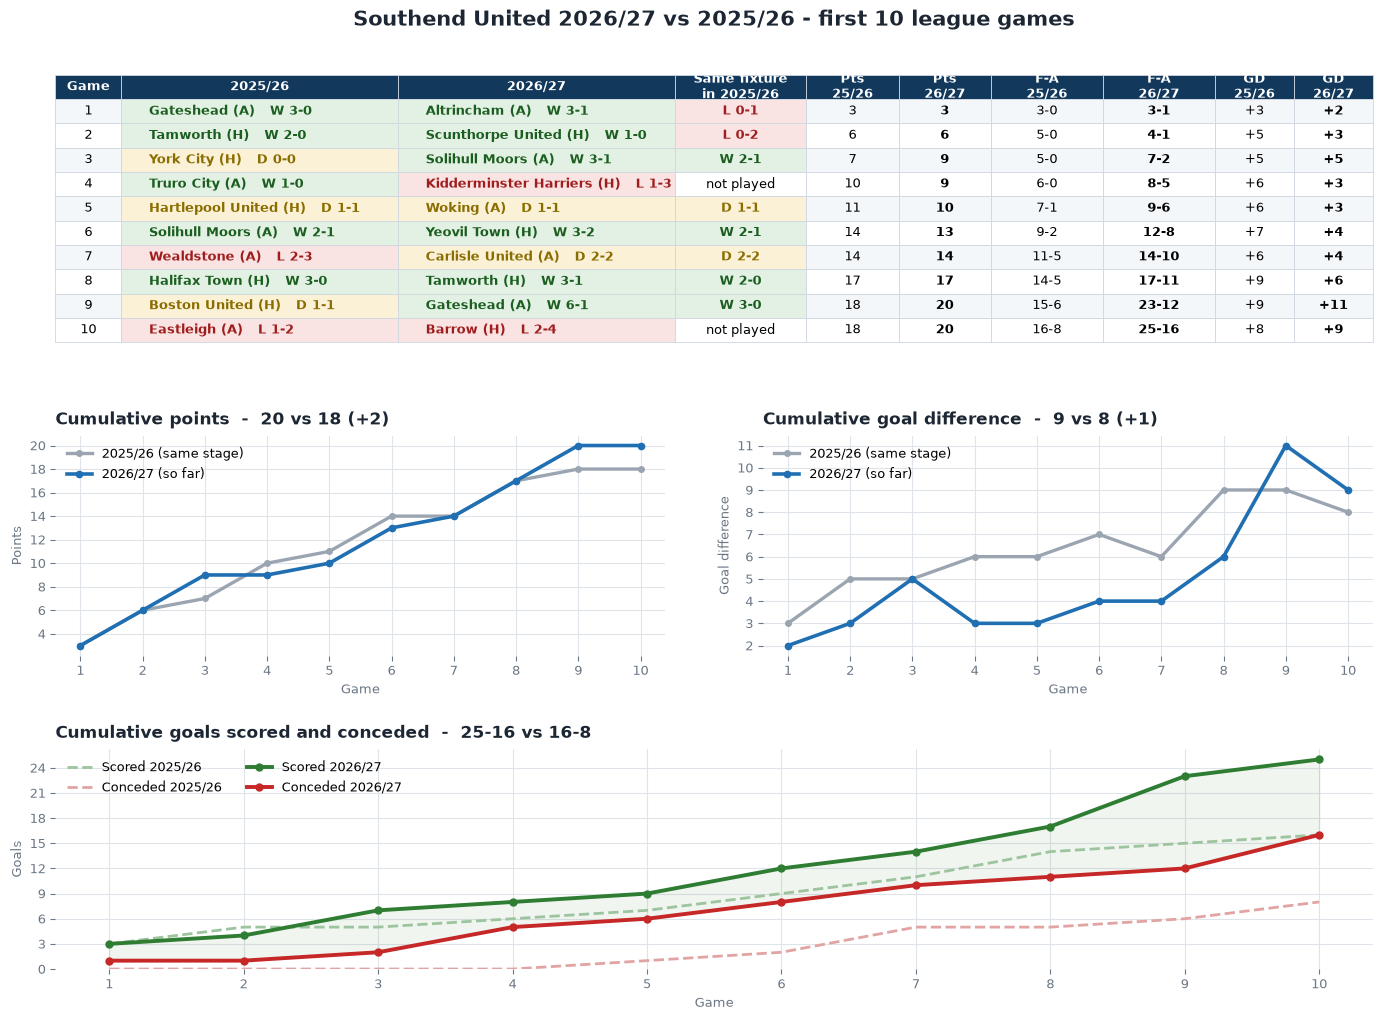

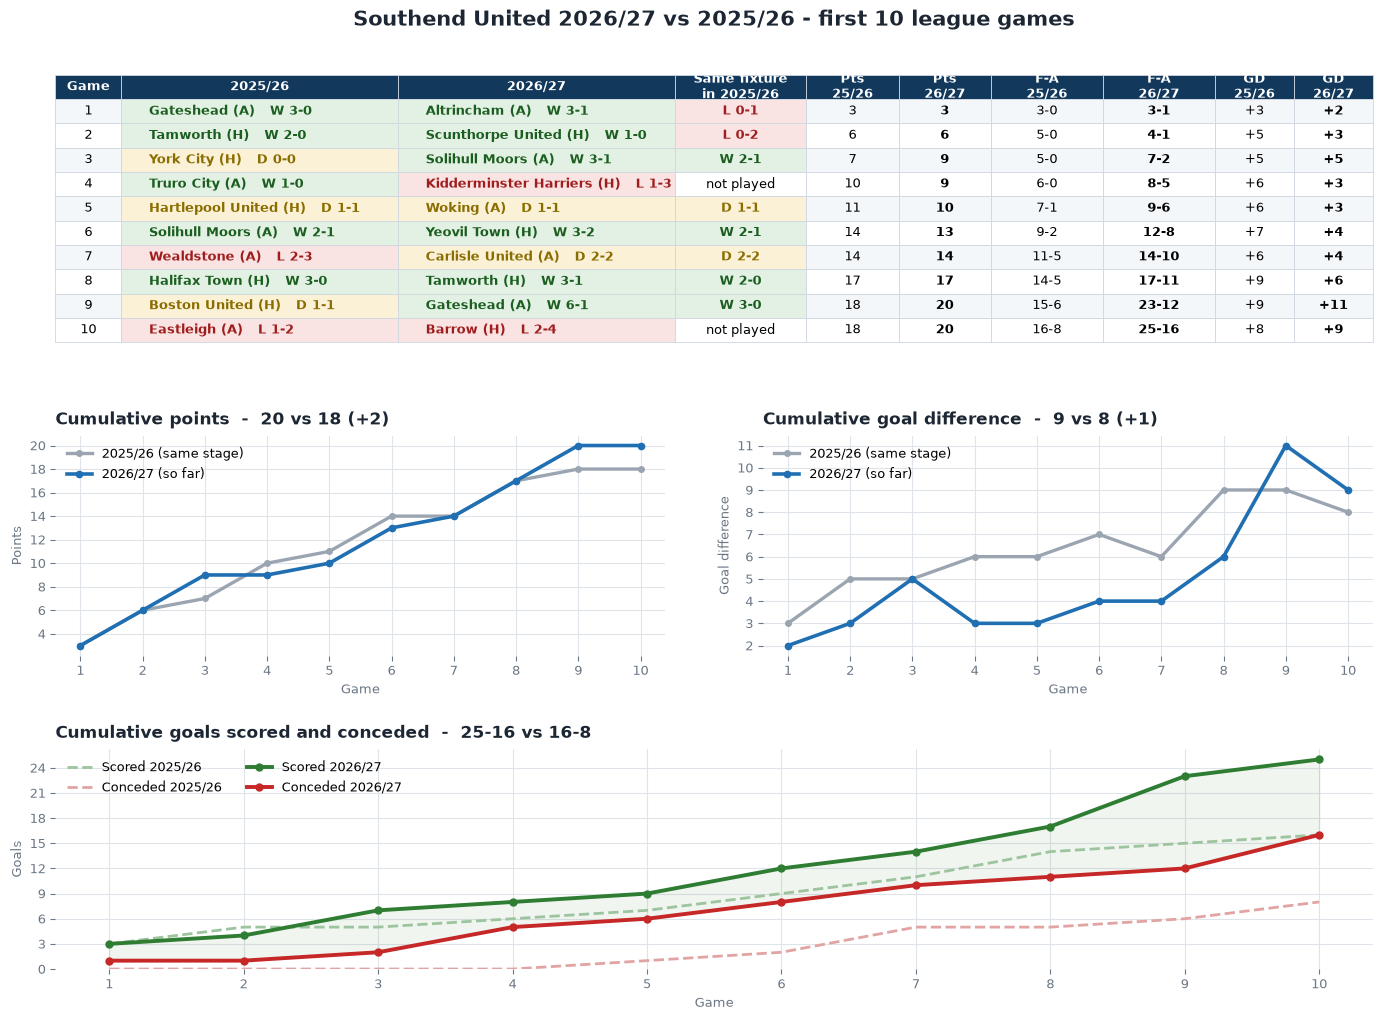

In [40]:
season.season_comparison(SOUTHEND, SEASON, SEASON_2025)

## `season.league_position` - position and the gap to the top

The division's table is rebuilt after each of our match days. Position after every match with
the promotion and play-off places shaded, then points and goal difference against the leaders
(above the line is better; gold marks the days we were top). `promotion_places` and
`playoff_places` set the shading; `teams_in_league` the axis.

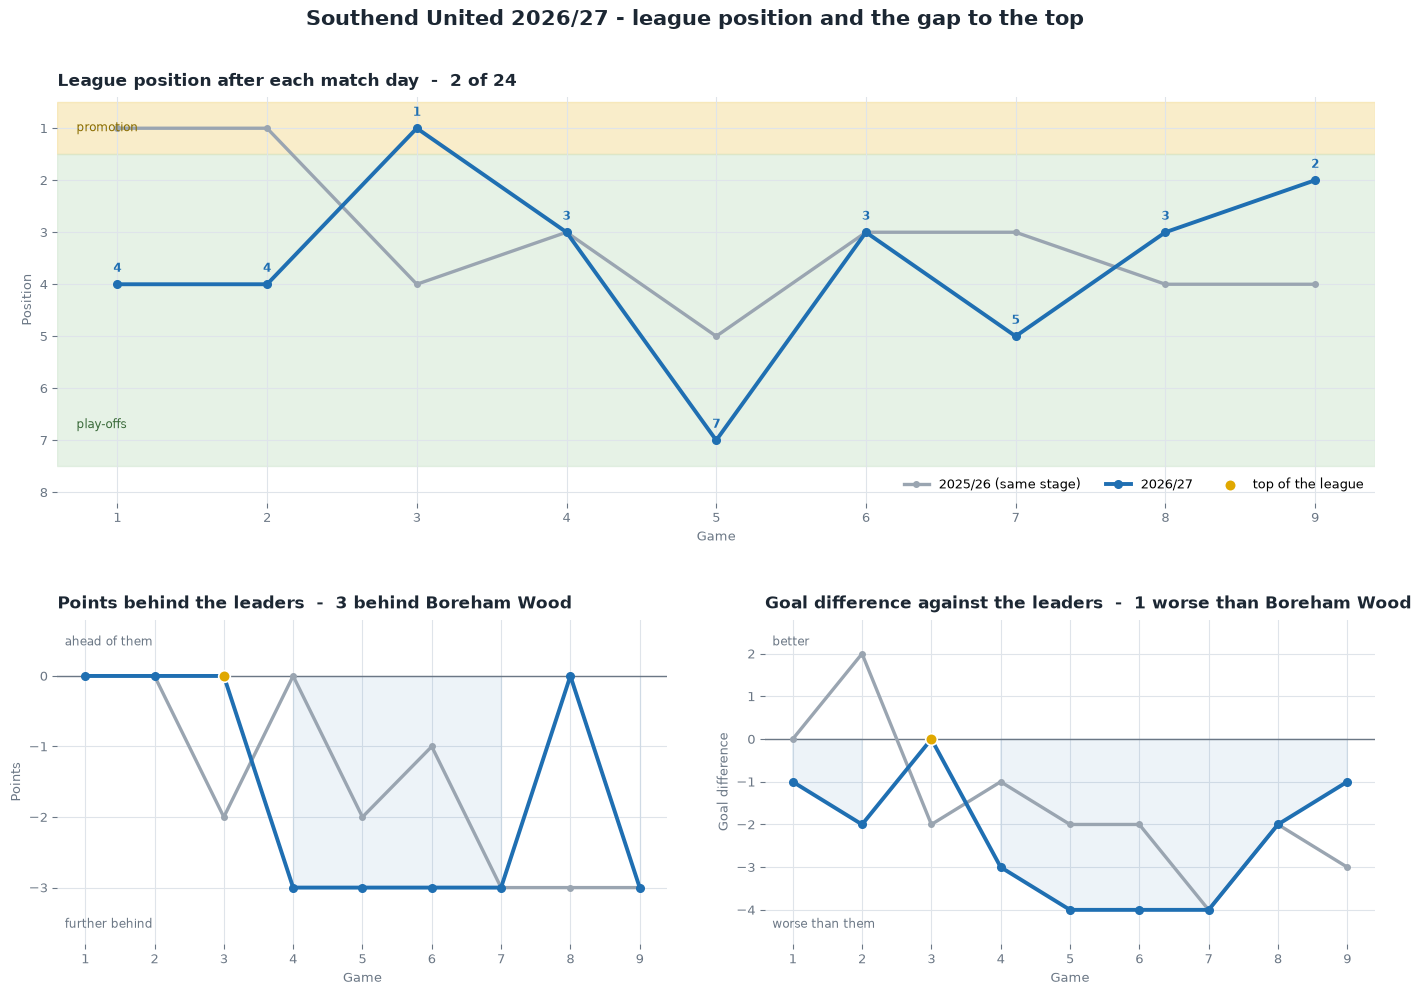

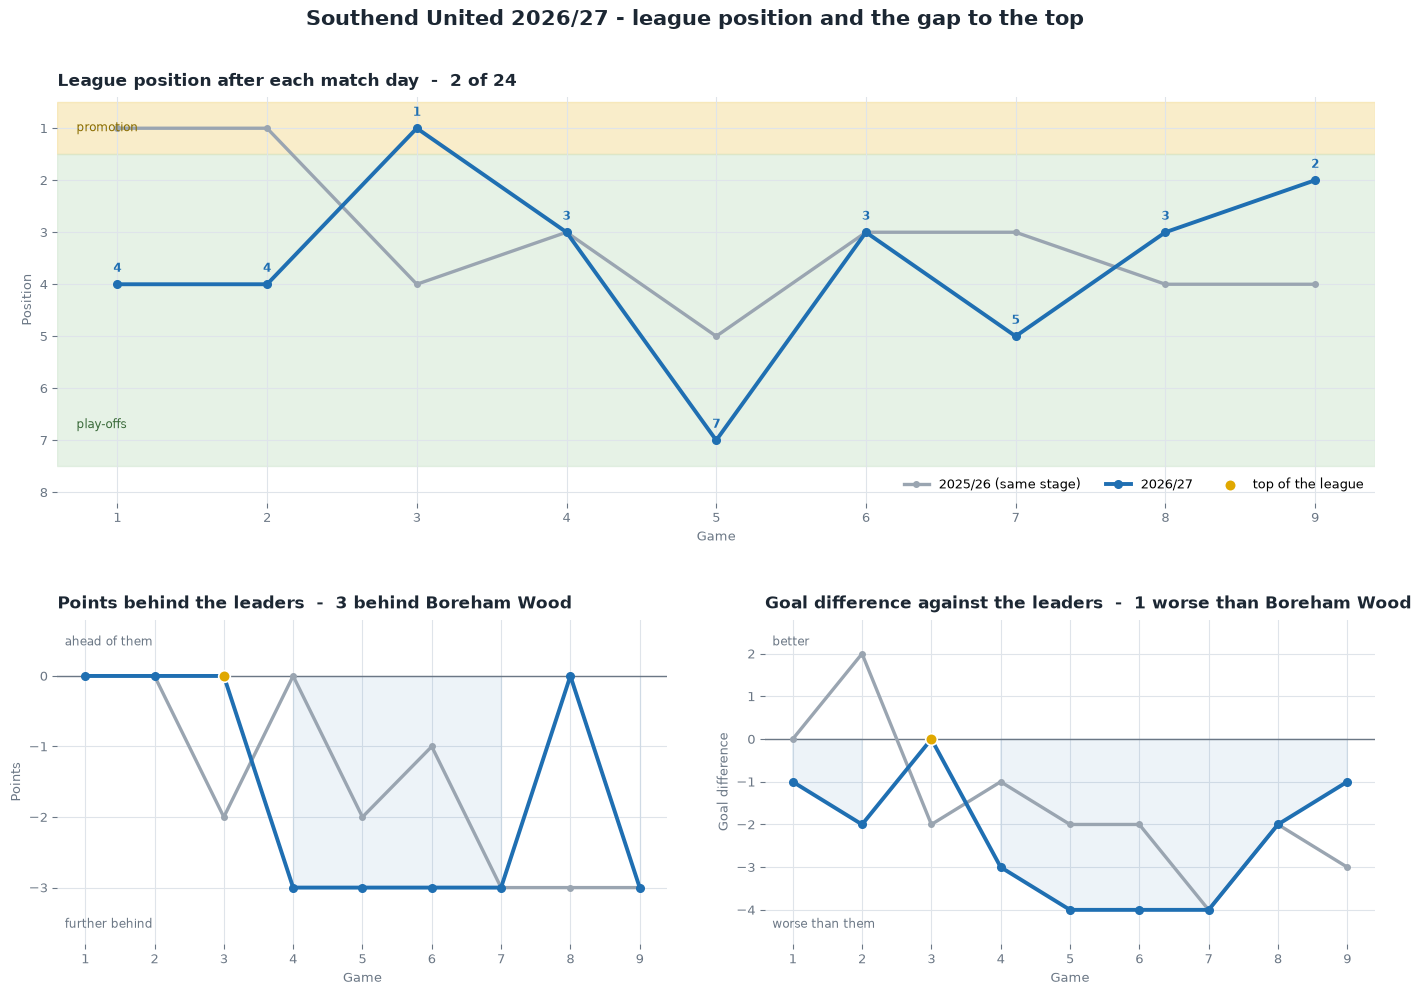

In [41]:
season.league_position(SOUTHEND, SEASON, PREV_SEASON, NATIONAL_LEAGUE)

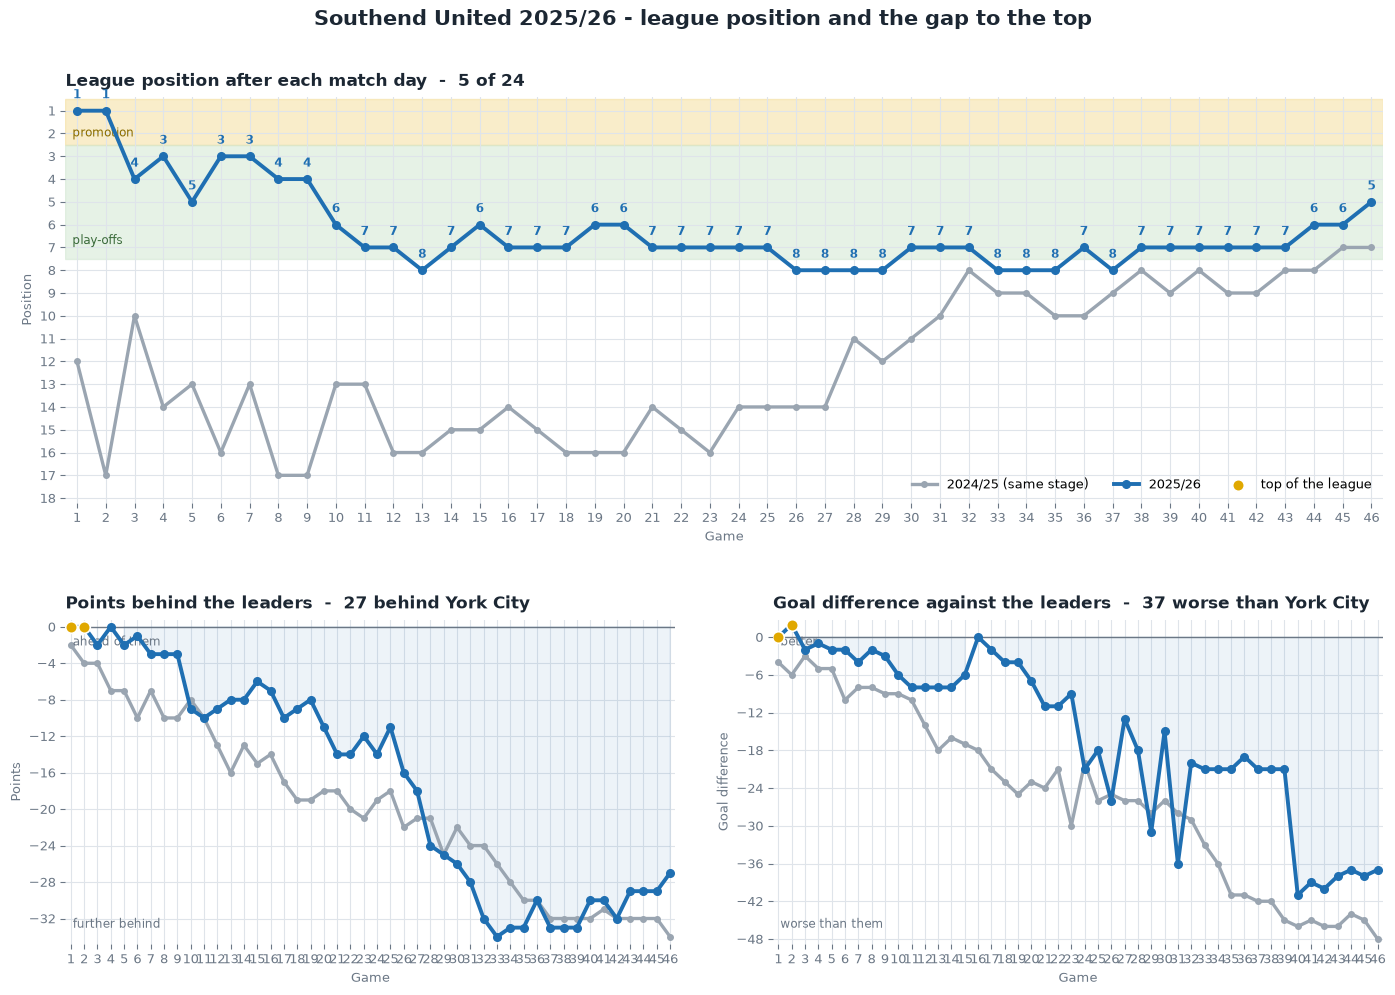

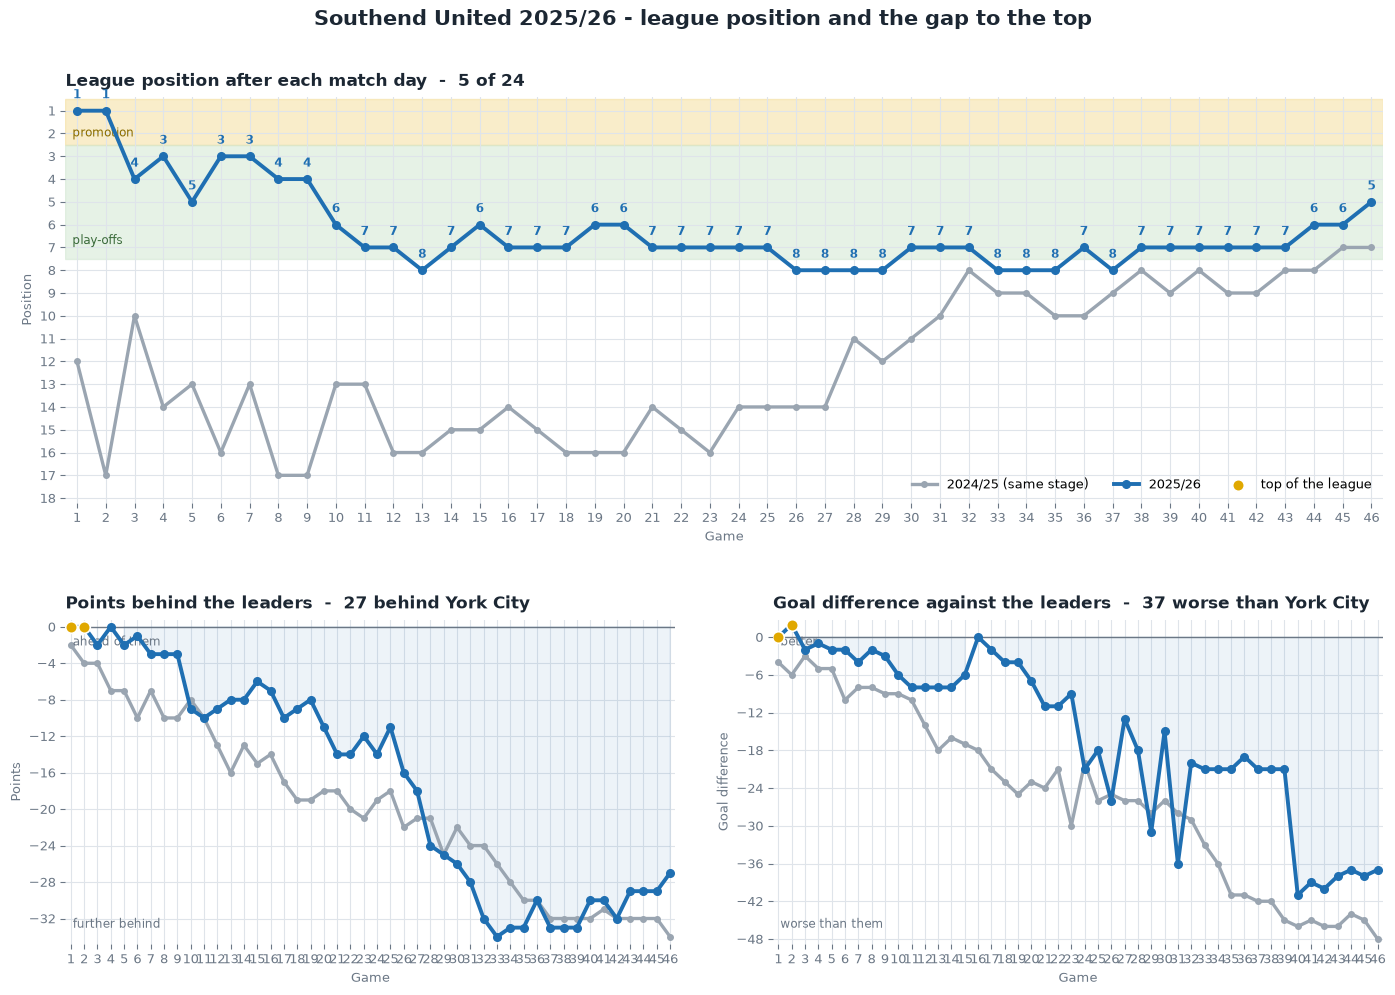

In [28]:
season.league_position(SOUTHEND, PREV_SEASON, SEASON_2024, NATIONAL_LEAGUE, promotion_places=2, playoff_places=7)

## `season.possession_histogram` - possession share per match

Matches binned by possession percentage, one colour per team. `teams` is `{id: label}`.

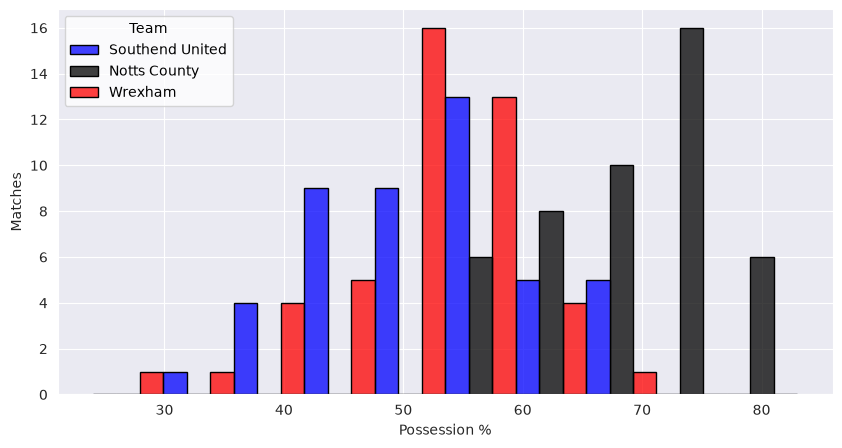

<Axes: xlabel='Possession %', ylabel='Matches'>

In [29]:
season.possession_histogram({SOUTHEND: "Southend United", NOTTS_COUNTY: "Notts County", WREXHAM: "Wrexham"},
                            SEASON_2022, palette=["blue", "black", "red"])

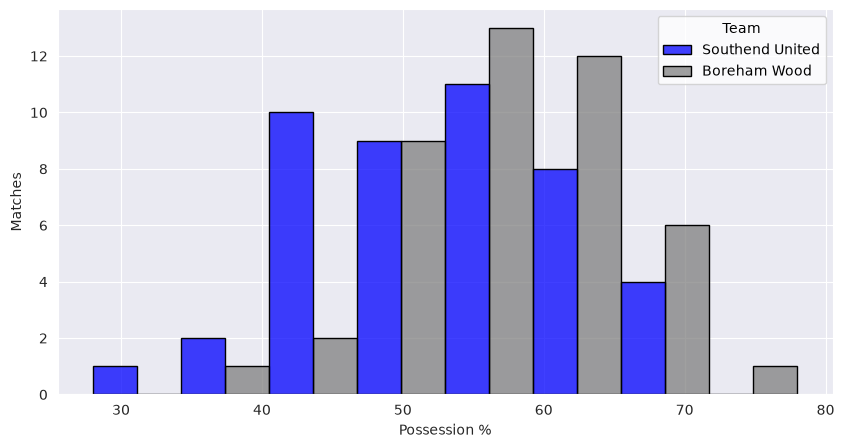

<Axes: xlabel='Possession %', ylabel='Matches'>

In [30]:
season.possession_histogram({SOUTHEND: "Southend United", BOREHAM_WOOD: "Boreham Wood"}, PREV_SEASON,
                            palette=["blue", "grey"], bins=8)

## `team.squad_grid` and `team.birth_months`

The squad as photos in appearance order with games and minutes, and the month-of-birth
distribution.

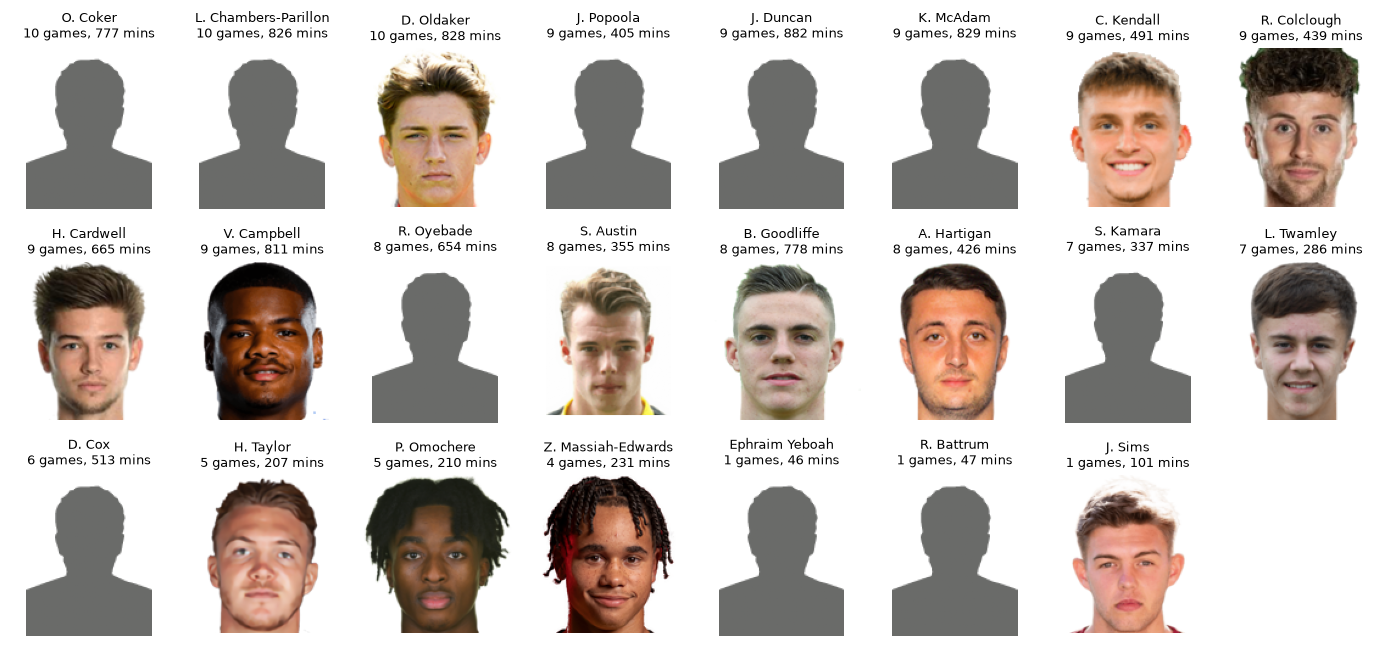

(<Figure size 1400x656.25 with 24 Axes>,
 array([<Axes: title={'center': 'O. Coker\n10 games, 777 mins'}>,
        <Axes: title={'center': 'L. Chambers-Parillon\n10 games, 826 mins'}>,
        <Axes: title={'center': 'D. Oldaker\n10 games, 828 mins'}>,
        <Axes: title={'center': 'J. Popoola\n9 games, 405 mins'}>,
        <Axes: title={'center': 'J. Duncan\n9 games, 882 mins'}>,
        <Axes: title={'center': 'K. McAdam\n9 games, 829 mins'}>,
        <Axes: title={'center': 'C. Kendall\n9 games, 491 mins'}>,
        <Axes: title={'center': 'R. Colclough\n9 games, 439 mins'}>,
        <Axes: title={'center': 'H. Cardwell\n9 games, 665 mins'}>,
        <Axes: title={'center': 'V. Campbell\n9 games, 811 mins'}>,
        <Axes: title={'center': 'R. Oyebade\n8 games, 654 mins'}>,
        <Axes: title={'center': 'S. Austin\n8 games, 355 mins'}>,
        <Axes: title={'center': 'B. Goodliffe\n8 games, 778 mins'}>,
        <Axes: title={'center': 'A. Hartigan\n8 games, 426 mins'}>,
      

In [31]:
team.squad_grid(SOUTHEND, SEASON, NATIONAL_LEAGUE, cols=8)

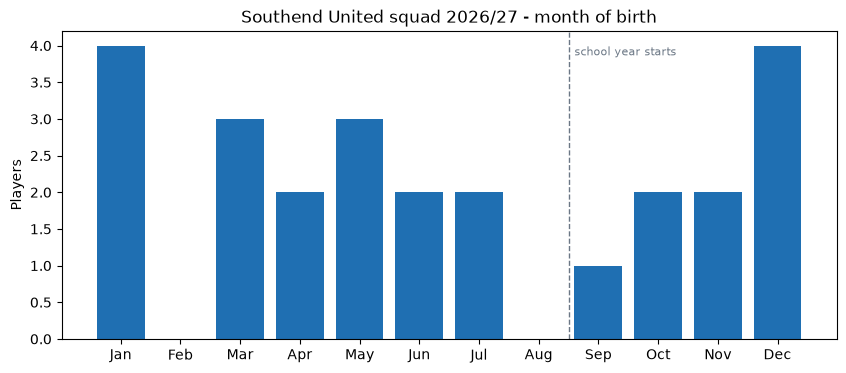

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Southend United squad 2026/27 - month of birth'}, ylabel='Players'>)

In [32]:
team.birth_months(SOUTHEND, SEASON)

## The data behind the charts

Everything above is drawn from these `wyscout.data.season` functions, which return plain
DataFrames or lists. Useful on their own for tables, exports or your own charts.

In [33]:
from wyscout.data.season import (
    goals_by_xg, goals_from_corners, season_results, season_shot_table, touches_in_box,
)

display(season_results(SOUTHEND, SEASON).tail(3))
display(season_shot_table(SOUTHEND, SEASON).round(2).tail(3))
display(goals_by_xg(SOUTHEND, SEASON).head(5))
display(goals_from_corners(SOUTHEND, SEASON))
print("touches in the box:", touches_in_box(SOUTHEND, SEASON))

,game,match_id,date,opponent,venue,label,gf,ga,gd,result,points,cum_gf,cum_ga,cum_gd
7,8,5864944,2026-09-15,Tamworth,H,Tamworth (H),3,1,2,W,17,17,11,6
8,9,5864960,2026-09-19,Gateshead,A,Gateshead (A),6,1,5,W,20,23,12,11
9,10,5864971,2026-09-26,Barrow,H,Barrow (H),2,4,-2,L,20,25,16,9


,game,match_id,date,label,short_label,result,shots,goals,xG,post_shot_xG,xg_per_shot,rolling_xg_per_shot,rolling_5_xg_per_shot,cum_xG,cum_goals
7,8,5864944,2026-09-15,Tamworth (H) W 3-1,vs Tamworth,2,27,3,3.02,3.06,0.11,0.14,0.14,16.15,15
8,9,5864960,2026-09-19,Gateshead (A) W 6-1,@ Gateshead,2,13,6,1.60,4.86,0.12,0.14,0.13,17.76,21
9,10,5864971,2026-09-26,Barrow (H) L 2-4,vs Barrow,0,11,1,1.23,0.83,0.11,0.13,0.11,18.98,22


,date,opponent,venue,scorer,minute,period,xG,type
0,2026-08-08,Altrincham,A,L. Chambers-Parillon,36,1H,0.01702,shot
1,2026-08-22,Solihull Moors,A,C. Kendall,91,2H,0.02897,shot
2,2026-09-19,Gateshead,A,S. Austin,41,1H,0.03189,shot
3,2026-09-15,Tamworth,H,L. Chambers-Parillon,59,2H,0.07567,shot
4,2026-09-12,Carlisle United,A,K. McAdam,91,2H,0.08757,shot


,date,opponent,venue,for,taker,minute
0,2026-09-05,Yeovil Town,H,True,K. McAdam,84
1,2026-09-12,Carlisle United,A,True,A. Hartigan,91
2,2026-09-26,Barrow,H,True,S. Kamara,91


touches in the box: {'L. Chambers-Parillon': 38, 'H. Cardwell': 31, 'K. McAdam': 27, 'R. Colclough': 25, 'P. Omochere': 20, 'J. Popoola': 19, 'V. Campbell': 18, 'S. Kamara': 16, 'Z. Massiah-Edwards': 15, 'S. Austin': 12, 'O. Coker': 11, 'L. Twamley': 8, 'B. Goodliffe': 5, 'C. Kendall': 4, 'D. Oldaker': 4, 'D. Cox': 3, 'R. Battrum': 3, 'A. Hartigan': 1, 'H. Taylor': 1}


In [34]:
from wyscout.league_table import table_progression

pd.DataFrame(table_progression(SEASON, NATIONAL_LEAGUE, SOUTHEND)).set_index("game")

,date,opponent,venue,score,position,played,points,goals_for,goals_against,goal_difference,is_leader,leader,leader_played,leader_points,leader_goal_difference,points_behind,goal_difference_behind
game,,,,,,,,,,,,,,,,,
1,2026-08-08,Altrincham,A,3-1,4,1,3,3,1,2,False,Harrogate Town,1,3,3,0,1
2,2026-08-15,Scunthorpe United,H,1-0,4,2,6,4,1,3,False,Harrogate Town,2,6,5,0,2
3,2026-08-22,Solihull Moors,A,3-1,1,3,9,7,2,5,True,Sutton United,3,9,5,0,0
4,2026-08-28,Kidderminster Harriers,H,1-3,3,4,9,8,5,3,False,Sutton United,4,12,6,3,3
5,2026-08-31,Woking,A,1-1,7,5,10,9,6,3,False,Boreham Wood,5,13,7,3,4
6,2026-09-05,Yeovil Town,H,3-2,3,6,13,12,8,4,False,Boreham Wood,6,16,8,3,4
7,2026-09-12,Carlisle United,A,2-2,5,7,14,14,10,4,False,Boreham Wood,7,17,8,3,4
8,2026-09-15,Tamworth,H,3-1,3,8,17,17,11,6,False,Fylde,8,17,8,0,2
9,2026-09-19,Gateshead,A,6-1,2,9,20,23,12,11,False,Boreham Wood,9,23,12,3,1
